In [1]:
# =============================================================================
# STEP 1: ENVIRONMENT SETUP
# =============================================================================

from pathlib import Path
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

# -----------------------------------------------------------------------------
# Reproducibility
# -----------------------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# -----------------------------------------------------------------------------
# Dataset path
# -----------------------------------------------------------------------------

DATASET_PATH = Path("/content/drive/MyDrive/Solar_panel_data-1")

# Mount Google Drive
from google.colab import drive

drive.mount("/content/drive")

# -----------------------------------------------------------------------------
# Output directories
# -----------------------------------------------------------------------------

OUTPUT_DIR = Path("/content/solar_pv_paper_outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
DATA_DIR = OUTPUT_DIR / "data"
RESULT_DIR = OUTPUT_DIR / "results"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset path :", DATASET_PATH)
print("Output path  :", OUTPUT_DIR)

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset directory not found:\n{DATASET_PATH}"
    )

print("\nDataset directory found successfully.")

Mounted at /content/drive
Dataset path : /content/drive/MyDrive/Solar_panel_data-1
Output path  : /content/solar_pv_paper_outputs

Dataset directory found successfully.


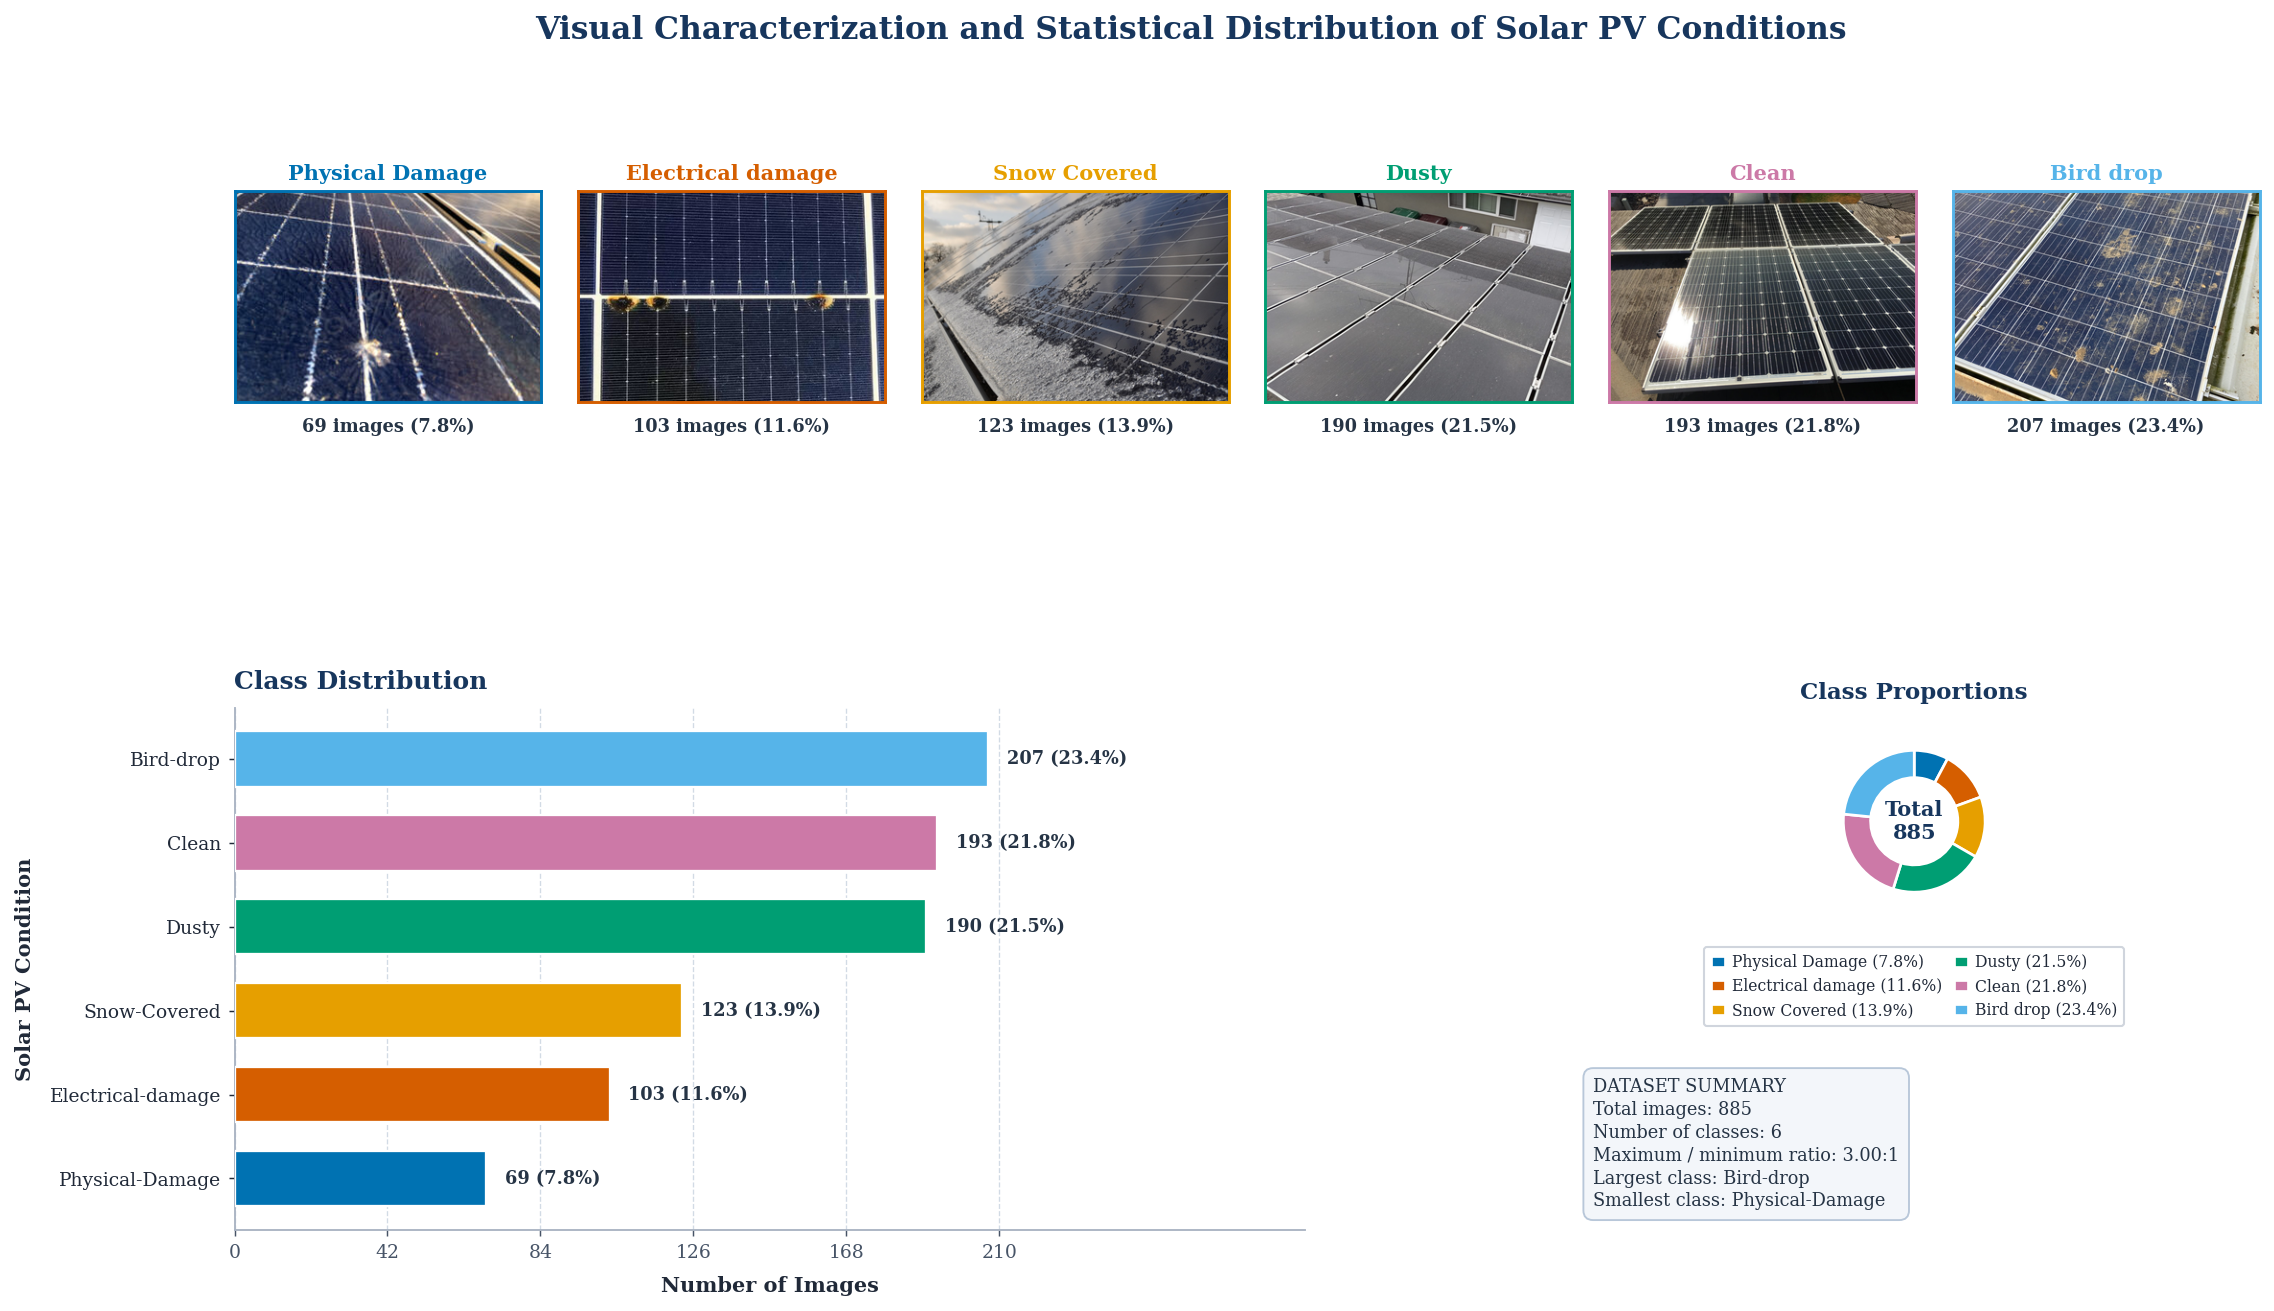

STEP 2 — VISUAL AND STATISTICAL CHARACTERIZATION COMPLETE
            Class  Image_Count  Percentage  Imbalance_Ratio
  Physical-Damage           69    7.796610         3.000000
Electrical-damage          103   11.638418         2.009709
     Snow-Covered          123   13.898305         1.682927
            Dusty          190   21.468927         1.089474
            Clean          193   21.807910         1.072539
        Bird-drop          207   23.389831         1.000000

FINAL SUMMARY
------------------------------------------------------------------------
Total images       : 885
Number of classes  : 6
Maximum class      : Bird-drop (207)
Minimum class      : Physical-Damage (69)
Max/min ratio      : 3.00:1

OUTPUT FILES
------------------------------------------------------------------------
PNG : /content/solar_pv_paper_outputs/figures/Figure_1_Visual_Statistical_Profile.png
PDF : /content/solar_pv_paper_outputs/figures/Figure_1_Visual_Statistical_Profile.pdf
CSV : /content/solar

In [9]:

# =============================================================================
# STEP 2 — VISUAL AND STATISTICAL DATASET CHARACTERIZATION
# Compact, IEEE-Style Composite Figure Using Actual Dataset Images
# =============================================================================

from pathlib import Path
import math

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from PIL import Image, ImageOps

# =============================================================================
# 1. PUBLICATION-READY TYPOGRAPHY
# =============================================================================

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",
        "Times",
        "DejaVu Serif",
        "Nimbus Roman No9 L",
    ],
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 12,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# =============================================================================
# 2. VALIDATE DATASET AND OUTPUT DIRECTORIES
# =============================================================================

if not DATASET_PATH.is_dir():
    raise FileNotFoundError(
        f"Dataset directory not found: {DATASET_PATH}"
    )

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp",
}

# =============================================================================
# 3. DISCOVER CLASS FOLDERS AND IMAGE FILES
# =============================================================================

class_files = {}

for folder in sorted(DATASET_PATH.iterdir()):
    if not folder.is_dir():
        continue

    image_paths = sorted(
        path
        for path in folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    )

    if image_paths:
        class_files[folder.name] = image_paths

if not class_files:
    raise ValueError(
        "No image files were found inside class subfolders. "
        "Verify the dataset directory structure."
    )

# Sort classes by image count, ascending.
class_files = dict(
    sorted(
        class_files.items(),
        key=lambda item: len(item[1]),
    )
)

class_names = list(class_files.keys())

counts = np.array(
    [len(class_files[name]) for name in class_names],
    dtype=int,
)

total_images = int(counts.sum())
n_classes = len(class_names)

percentages = (
    100.0 * counts / total_images
)

imbalance_ratio = (
    float(counts.max()) / float(counts.min())
)

# =============================================================================
# 4. SAVE EXACT CLASS STATISTICS
# =============================================================================

stats_df = pd.DataFrame({
    "Class": class_names,
    "Image_Count": counts,
    "Percentage": percentages,
    "Imbalance_Ratio": counts.max() / counts,
})

stats_df.to_csv(
    DATA_DIR / "Figure_1_Class_Statistics.csv",
    index=False,
)

# =============================================================================
# 5. CONSISTENT CLASS COLORS
# =============================================================================

# Known solar-panel classes receive consistent colors.
# Unrecognized classes receive deterministic fallback colors.

known_palette = {
    "physical-damage": "#0072B2",
    "electrical-damage": "#D55E00",
    "snow-covered": "#E69F00",
    "dusty": "#009E73",
    "clean": "#CC79A7",
    "bird-drop": "#56B4E9",
}

fallback_palette = [
    "#6B7280",
    "#8C6BB1",
    "#A6761D",
    "#1B9E77",
]

def normalize_class_name(name: str) -> str:
    """Normalize class names for robust palette matching."""
    return (
        name.strip()
        .lower()
        .replace("_", "-")
        .replace(" ", "-")
    )

class_colors = {}

for index, name in enumerate(class_names):
    normalized_name = normalize_class_name(name)

    if normalized_name in known_palette:
        class_colors[name] = known_palette[normalized_name]
    else:
        class_colors[name] = fallback_palette[
            index % len(fallback_palette)
        ]

# =============================================================================
# 6. REPRODUCIBLE REPRESENTATIVE IMAGE SELECTION
# =============================================================================

representative_images = {}

for index, class_name in enumerate(class_names):
    paths = class_files[class_name]

    rng = np.random.default_rng(SEED + index)

    sample_index = int(
        rng.integers(0, len(paths))
    )

    representative_images[class_name] = paths[sample_index]

# =============================================================================
# 7. FIGURE CANVAS AND COMPACT LAYOUT
# =============================================================================

# The lower-right panel receives extra height to avoid legend/summary overlap.
# Constrained layout is intentionally not enabled because the figure uses
# explicit GridSpec geometry and controlled margins.

fig = plt.figure(
    figsize=(15, 9.0),
    facecolor="white",
)

fig.suptitle(
    "Visual Characterization and Statistical Distribution "
    "of Solar PV Conditions",
    fontsize=15,
    fontweight="bold",
    color="#17365D",
    y=0.975,
)

outer_grid = fig.add_gridspec(
    nrows=2,
    ncols=2,
    left=0.075,
    right=0.975,
    bottom=0.075,
    top=0.91,
    height_ratios=[1.0, 1.35],
    width_ratios=[1.55, 1.0],
    hspace=0.48,
    wspace=0.30,
)

# =============================================================================
# 8. TOP PANEL — REPRESENTATIVE REAL DATASET IMAGES
# =============================================================================

n_cols = min(n_classes, 6)
n_rows = math.ceil(n_classes / n_cols)

image_grid = outer_grid[0, :].subgridspec(
    nrows=n_rows,
    ncols=n_cols,
    wspace=0.12,
    hspace=0.35,
)

for index, class_name in enumerate(class_names):
    row, col = divmod(index, n_cols)

    ax = fig.add_subplot(image_grid[row, col])

    image_path = representative_images[class_name]

    try:
        with Image.open(image_path) as source:
            image = ImageOps.exif_transpose(
                source
            ).convert("RGB")

            image = ImageOps.fit(
                image,
                (320, 220),
                method=Image.Resampling.LANCZOS,
            )

            ax.imshow(image)

    except (OSError, ValueError) as error:
        ax.text(
            0.5,
            0.5,
            f"Image unavailable\n{error}",
            transform=ax.transAxes,
            ha="center",
            va="center",
            fontsize=8,
            wrap=True,
        )

    ax.set_title(
        class_name.replace("_", " ").replace("-", " "),
        fontsize=10,
        fontweight="bold",
        color=class_colors[class_name],
        pad=5,
    )

    ax.text(
        0.5,
        -0.075,
        f"{len(class_files[class_name]):,} images "
        f"({100.0 * len(class_files[class_name]) / total_images:.1f}%)",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=8.5,
        fontweight="bold",
        color="#263445",
    )

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(class_colors[class_name])
        spine.set_linewidth(1.4)

# =============================================================================
# 9. BOTTOM LEFT — CLASS DISTRIBUTION
# =============================================================================

ax_bar = fig.add_subplot(outer_grid[1, 0])

bars = ax_bar.barh(
    class_names,
    counts,
    height=0.66,
    color=[
        class_colors[name]
        for name in class_names
    ],
    edgecolor="white",
    linewidth=1.1,
    zorder=3,
)

max_count = int(counts.max())

for bar, count, percentage in zip(
    bars,
    counts,
    percentages,
):
    ax_bar.text(
        bar.get_width() + max_count * 0.025,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,} ({percentage:.1f}%)",
        ha="left",
        va="center",
        fontsize=8.5,
        fontweight="bold",
        color="#263445",
        clip_on=False,
    )

ax_bar.set_title(
    "Class Distribution",
    loc="left",
    fontsize=12,
    fontweight="bold",
    color="#17365D",
    pad=9,
)

ax_bar.set_xlabel(
    "Number of Images",
    fontweight="bold",
    labelpad=7,
)

ax_bar.set_ylabel(
    "Solar PV Condition",
    fontweight="bold",
    labelpad=7,
)

ax_bar.set_xlim(
    0,
    max_count * 1.42,
)

tick_step = max(1, int(math.ceil(max_count / 5)))

ax_bar.set_xticks(
    np.arange(
        0,
        max_count + tick_step,
        tick_step,
    )
)

ax_bar.grid(
    axis="x",
    linestyle="--",
    linewidth=0.65,
    color="#CBD5E1",
    alpha=0.85,
    zorder=0,
)

ax_bar.set_axisbelow(True)

ax_bar.tick_params(
    axis="both",
    direction="out",
    length=3,
    width=0.7,
)

ax_bar.spines["left"].set_color("#AAB4C3")
ax_bar.spines["bottom"].set_color("#AAB4C3")

# =============================================================================
# 10. BOTTOM RIGHT — DONUT CHART
# =============================================================================

right_grid = outer_grid[1, 1].subgridspec(
    nrows=2,
    ncols=1,
    height_ratios=[1.45, 1.0],
    hspace=0.72,
)

ax_donut = fig.add_subplot(right_grid[0, 0])

wedges, _ = ax_donut.pie(
    counts,
    startangle=90,
    counterclock=False,
    colors=[
        class_colors[name]
        for name in class_names
    ],
    radius=0.78,
    wedgeprops={
        "width": 0.30,
        "edgecolor": "white",
        "linewidth": 1.3,
    },
)

ax_donut.text(
    0,
    0,
    f"Total\n{total_images:,}",
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color="#17365D",
)

ax_donut.set_title(
    "Class Proportions",
    fontsize=11,
    fontweight="bold",
    color="#17365D",
    pad=4,
)

legend_labels = [
    f"{name.replace('_', ' ').replace('-', ' ')} "
    f"({percentage:.1f}%)"
    for name, percentage in zip(
        class_names,
        percentages,
    )
]

# Reserve a dedicated region below the donut for the legend.
ax_donut.legend(
    wedges,
    legend_labels,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=2,
    fontsize=7.5,
    frameon=True,
    framealpha=1.0,
    facecolor="white",
    edgecolor="#D0D5DD",
    borderpad=0.45,
    labelspacing=0.45,
    columnspacing=0.7,
    handlelength=0.9,
    handletextpad=0.45,
)

# =============================================================================
# 11. BOTTOM RIGHT — DATASET SUMMARY
# =============================================================================

ax_summary = fig.add_subplot(right_grid[1, 0])

ax_summary.set_axis_off()

largest_class = class_names[int(np.argmax(counts))]
smallest_class = class_names[int(np.argmin(counts))]

summary_text = (
    "DATASET SUMMARY\n"
    f"Total images: {total_images:,}\n"
    f"Number of classes: {n_classes}\n"
    f"Maximum / minimum ratio: {imbalance_ratio:.2f}:1\n"
    f"Largest class: {largest_class}\n"
    f"Smallest class: {smallest_class}"
)

ax_summary.text(
    0.035,
    0.97,
    summary_text,
    transform=ax_summary.transAxes,
    ha="left",
    va="top",
    fontsize=8.5,
    linespacing=1.35,
    color="#263445",
    bbox={
        "boxstyle": "round,pad=0.55",
        "facecolor": "#F3F6FA",
        "edgecolor": "#B8C7D9",
        "linewidth": 0.9,
    },
)

# =============================================================================
# 12. EXPORT PUBLICATION-READY FIGURES
# =============================================================================

png_path = (
    FIGURE_DIR /
    "Figure_1_Visual_Statistical_Profile.png"
)

pdf_path = (
    FIGURE_DIR /
    "Figure_1_Visual_Statistical_Profile.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.15,
    facecolor="white",
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    pad_inches=0.15,
    facecolor="white",
)

plt.show()
plt.close(fig)

# =============================================================================
# 13. REPORT AND SAVE FINAL STATISTICS
# =============================================================================

print("=" * 72)
print("STEP 2 — VISUAL AND STATISTICAL CHARACTERIZATION COMPLETE")
print("=" * 72)

print(stats_df.to_string(index=False))

print("\nFINAL SUMMARY")
print("-" * 72)
print(f"Total images       : {total_images:,}")
print(f"Number of classes  : {n_classes}")
print(f"Maximum class      : {largest_class} ({counts.max():,})")
print(f"Minimum class      : {smallest_class} ({counts.min():,})")
print(f"Max/min ratio      : {imbalance_ratio:.2f}:1")

print("\nOUTPUT FILES")
print("-" * 72)
print(f"PNG : {png_path}")
print(f"PDF : {pdf_path}")
print(f"CSV : {DATA_DIR / 'Figure_1_Class_Statistics.csv'}")
print("=" * 72)

In [10]:
# =============================================================================
# STEP 2: DATASET STRUCTURE AUDIT
# =============================================================================

VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp",
}

class_dirs = sorted(
    [
        path
        for path in DATASET_PATH.iterdir()
        if path.is_dir()
    ]
)

if not class_dirs:
    raise RuntimeError(
        "No class folders were found inside the dataset directory."
    )

dataset_records = []

for class_dir in class_dirs:
    image_files = sorted(
        [
            path
            for path in class_dir.rglob("*")
            if path.is_file()
            and path.suffix.lower() in VALID_EXTENSIONS
        ]
    )

    for image_path in image_files:
        dataset_records.append(
            {
                "path": str(image_path),
                "class": class_dir.name,
            }
        )

dataset_df = pd.DataFrame(dataset_records)

if dataset_df.empty:
    raise RuntimeError("No valid image files were found.")

# -----------------------------------------------------------------------------
# Class statistics
# -----------------------------------------------------------------------------

class_counts = (
    dataset_df["class"]
    .value_counts()
    .sort_values(ascending=False)
)

total_images = len(dataset_df)

class_stats = pd.DataFrame(
    {
        "Class": class_counts.index,
        "Count": class_counts.values,
    }
)

class_stats["Percentage"] = (
    class_stats["Count"] / total_images * 100
)

class_stats["Relative_to_Max"] = (
    class_stats["Count"] / class_stats["Count"].max()
)

class_stats["Imbalance_Ratio_vs_Max"] = (
    class_stats["Count"].max() / class_stats["Count"]
)

print("=" * 70)
print("SOLAR PV DATASET AUDIT")
print("=" * 70)

print(f"Total images: {total_images}")
print(f"Number of classes: {len(class_stats)}")
print()

print(class_stats.to_string(index=False))

print("\nClass folders:")
for class_dir in class_dirs:
    print(" -", class_dir.name)

SOLAR PV DATASET AUDIT
Total images: 885
Number of classes: 6

            Class  Count  Percentage  Relative_to_Max  Imbalance_Ratio_vs_Max
        Bird-drop    207   23.389831         1.000000                1.000000
            Clean    193   21.807910         0.932367                1.072539
            Dusty    190   21.468927         0.917874                1.089474
     Snow-Covered    123   13.898305         0.594203                1.682927
Electrical-damage    103   11.638418         0.497585                2.009709
  Physical-Damage     69    7.796610         0.333333                3.000000

Class folders:
 - Bird-drop
 - Clean
 - Dusty
 - Electrical-damage
 - Physical-Damage
 - Snow-Covered


In [11]:
# =============================================================================
# STEP 4: MASTER DATASET INDEX
# =============================================================================

dataset_df["filename"] = dataset_df["path"].apply(
    lambda x: Path(x).name
)

dataset_df["class_id"] = (
    pd.Categorical(dataset_df["class"])
    .codes
)

# -----------------------------------------------------------------------------
# Canonical class ordering
# -----------------------------------------------------------------------------

preferred_order = [
    "Clean",
    "Bird-drop",
    "Dusty",
    "Snow-covered",
    "Physical-damage",
    "Physical-Damage",
    "Electrical-damage",
]

existing_classes = list(dataset_df["class"].unique())

ordered_classes = [
    cls for cls in preferred_order
    if cls in existing_classes
]

# Add anything unexpected
ordered_classes += [
    cls for cls in existing_classes
    if cls not in ordered_classes
]

class_to_id = {
    cls: idx
    for idx, cls in enumerate(ordered_classes)
}

dataset_df["class_id"] = dataset_df["class"].map(class_to_id)

# -----------------------------------------------------------------------------
# Save master metadata
# -----------------------------------------------------------------------------

MASTER_CSV = DATA_DIR / "solar_pv_master_metadata.csv"

dataset_df.to_csv(
    MASTER_CSV,
    index=False,
)

print("Master metadata saved to:")
print(MASTER_CSV)

print("\nFinal dataset shape:")
print(dataset_df.shape)

print("\nClass mapping:")
for class_name, class_id in class_to_id.items():
    print(f"{class_id}: {class_name}")

Master metadata saved to:
/content/solar_pv_paper_outputs/data/solar_pv_master_metadata.csv

Final dataset shape:
(885, 4)

Class mapping:
0: Clean
1: Bird-drop
2: Dusty
3: Physical-Damage
4: Electrical-damage
5: Snow-Covered


In [12]:
# =============================================================================
# STEP 2.1: STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# =============================================================================

from sklearn.model_selection import train_test_split

# -----------------------------------------------------------------------------
# Reproducibility
# -----------------------------------------------------------------------------

RANDOM_STATE = 42

# -----------------------------------------------------------------------------
# Check class distribution before splitting
# -----------------------------------------------------------------------------

print("=" * 75)
print("ORIGINAL DATASET DISTRIBUTION")
print("=" * 75)

original_distribution = (
    dataset_df["class"]
    .value_counts()
    .sort_index()
)

print(original_distribution)

# -----------------------------------------------------------------------------
# First split:
# 70% training
# 30% temporary set
# -----------------------------------------------------------------------------

train_df, temp_df = train_test_split(
    dataset_df,
    test_size=0.30,
    stratify=dataset_df["class"],
    random_state=RANDOM_STATE,
)

# -----------------------------------------------------------------------------
# Second split:
# 15% validation
# 15% test
#
# Since temp_df = 30% of complete dataset:
# 50% of temp_df = 15% of complete dataset
# -----------------------------------------------------------------------------

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class"],
    random_state=RANDOM_STATE,
)

# -----------------------------------------------------------------------------
# Reset indices
# -----------------------------------------------------------------------------

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# -----------------------------------------------------------------------------
# Print split sizes
# -----------------------------------------------------------------------------

print("\n" + "=" * 75)
print("DATASET SPLIT")
print("=" * 75)

print(f"Total      : {len(dataset_df)}")
print(f"Training   : {len(train_df)}")
print(f"Validation : {len(val_df)}")
print(f"Test       : {len(test_df)}")

print("\nPercentages:")

print(
    f"Training   : {len(train_df) / len(dataset_df) * 100:.2f}%"
)

print(
    f"Validation : {len(val_df) / len(dataset_df) * 100:.2f}%"
)

print(
    f"Test       : {len(test_df) / len(dataset_df) * 100:.2f}%"
)

ORIGINAL DATASET DISTRIBUTION
class
Bird-drop            207
Clean                193
Dusty                190
Electrical-damage    103
Physical-Damage       69
Snow-Covered         123
Name: count, dtype: int64

DATASET SPLIT
Total      : 885
Training   : 619
Validation : 133
Test       : 133

Percentages:
Training   : 69.94%
Validation : 15.03%
Test       : 15.03%


In [13]:
# =============================================================================
# STEP 2.2: VERIFY CLASS DISTRIBUTION ACROSS SPLITS
# =============================================================================

def get_split_distribution(
    dataframe: pd.DataFrame,
    split_name: str,
) -> pd.DataFrame:
    """
    Calculate class counts and percentages for a dataset split.
    """
    counts = (
        dataframe["class"]
        .value_counts()
        .reindex(ordered_classes, fill_value=0)
    )

    percentages = (
        counts / len(dataframe) * 100
    )

    return pd.DataFrame(
        {
            "Class": counts.index,
            "Count": counts.values,
            "Percentage": percentages.values,
            "Split": split_name,
        }
    )


train_distribution = get_split_distribution(
    train_df,
    "Train",
)

val_distribution = get_split_distribution(
    val_df,
    "Validation",
)

test_distribution = get_split_distribution(
    test_df,
    "Test",
)

split_distribution = pd.concat(
    [
        train_distribution,
        val_distribution,
        test_distribution,
    ],
    ignore_index=True,
)

print("=" * 75)
print("CLASS DISTRIBUTION BY SPLIT")
print("=" * 75)

print(
    split_distribution.to_string(index=False)
)

CLASS DISTRIBUTION BY SPLIT
            Class  Count  Percentage      Split
            Clean    135   21.809370      Train
        Bird-drop    145   23.424879      Train
            Dusty    133   21.486268      Train
  Physical-Damage     48    7.754443      Train
Electrical-damage     72   11.631664      Train
     Snow-Covered     86   13.893376      Train
            Clean     29   21.804511 Validation
        Bird-drop     31   23.308271 Validation
            Dusty     28   21.052632 Validation
  Physical-Damage     10    7.518797 Validation
Electrical-damage     16   12.030075 Validation
     Snow-Covered     19   14.285714 Validation
            Clean     29   21.804511       Test
        Bird-drop     31   23.308271       Test
            Dusty     29   21.804511       Test
  Physical-Damage     11    8.270677       Test
Electrical-damage     15   11.278195       Test
     Snow-Covered     18   13.533835       Test


In [14]:
# =============================================================================
# STEP 2.3: SPLIT SUMMARY TABLE
# =============================================================================

split_summary = pd.DataFrame(
    {
        "Dataset": [
            "Full Dataset",
            "Training",
            "Validation",
            "Test",
        ],
        "Images": [
            len(dataset_df),
            len(train_df),
            len(val_df),
            len(test_df),
        ],
    }
)

split_summary["Percentage"] = (
    split_summary["Images"]
    / len(dataset_df)
    * 100
)

print(
    split_summary.to_string(index=False)
)

     Dataset  Images  Percentage
Full Dataset     885  100.000000
    Training     619   69.943503
  Validation     133   15.028249
        Test     133   15.028249


In [15]:
# =============================================================================
# STEP 2.4: SAVE REPRODUCIBLE DATA SPLITS
# =============================================================================

TRAIN_CSV = DATA_DIR / "train_split.csv"
VAL_CSV = DATA_DIR / "validation_split.csv"
TEST_CSV = DATA_DIR / "test_split.csv"

train_df.to_csv(
    TRAIN_CSV,
    index=False,
)

val_df.to_csv(
    VAL_CSV,
    index=False,
)

test_df.to_csv(
    TEST_CSV,
    index=False,
)

print("Saved dataset splits:")
print(f"Train      : {TRAIN_CSV}")
print(f"Validation : {VAL_CSV}")
print(f"Test       : {TEST_CSV}")

Saved dataset splits:
Train      : /content/solar_pv_paper_outputs/data/train_split.csv
Validation : /content/solar_pv_paper_outputs/data/validation_split.csv
Test       : /content/solar_pv_paper_outputs/data/test_split.csv


In [16]:
# =============================================================================
# STEP 2.5: CHECK FOR CROSS-SPLIT FILE DUPLICATES
# =============================================================================

train_paths = set(train_df["path"])
val_paths = set(val_df["path"])
test_paths = set(test_df["path"])

train_val_overlap = train_paths.intersection(val_paths)
train_test_overlap = train_paths.intersection(test_paths)
val_test_overlap = val_paths.intersection(test_paths)

print("=" * 75)
print("CROSS-SPLIT LEAKAGE CHECK")
print("=" * 75)

print(
    f"Train ∩ Validation : {len(train_val_overlap)}"
)

print(
    f"Train ∩ Test       : {len(train_test_overlap)}"
)

print(
    f"Validation ∩ Test  : {len(val_test_overlap)}"
)

if (
    len(train_val_overlap) == 0
    and len(train_test_overlap) == 0
    and len(val_test_overlap) == 0
):
    print("\n✓ No identical file paths occur across splits.")
else:
    raise RuntimeError(
        "Potential data leakage detected between dataset splits."
    )

CROSS-SPLIT LEAKAGE CHECK
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0

✓ No identical file paths occur across splits.


In [17]:
# =============================================================================
# STEP 2.8: PYTORCH IMAGE PREPROCESSING
# =============================================================================

import torch
from torchvision import transforms

# -----------------------------------------------------------------------------
# Image configuration
# -----------------------------------------------------------------------------

IMAGE_SIZE = 224

# -----------------------------------------------------------------------------
# ImageNet normalization
# -----------------------------------------------------------------------------

IMAGENET_MEAN = (
    0.485,
    0.456,
    0.406,
)

IMAGENET_STD = (
    0.229,
    0.224,
    0.225,
)

# -----------------------------------------------------------------------------
# Training transformations
# -----------------------------------------------------------------------------

train_transform = transforms.Compose(
    [
        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        ),

        transforms.RandomHorizontalFlip(
            p=0.5
        ),

        transforms.RandomRotation(
            degrees=10
        ),

        transforms.ColorJitter(
            brightness=0.15,
            contrast=0.15,
            saturation=0.10,
            hue=0.02,
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

# -----------------------------------------------------------------------------
# Validation transformations
# -----------------------------------------------------------------------------

val_transform = transforms.Compose(
    [
        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

# -----------------------------------------------------------------------------
# Test transformations
# -----------------------------------------------------------------------------

test_transform = transforms.Compose(
    [
        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

print("Image preprocessing configured.")
print(f"Input size: {IMAGE_SIZE} × {IMAGE_SIZE}")

Image preprocessing configured.
Input size: 224 × 224


In [18]:
# =============================================================================
# STEP 2 RECOVERY: PYTORCH DATASET + DATALOADERS
# =============================================================================

from typing import Optional, Callable

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image


# =============================================================================
# 1. CONFIGURATION
# =============================================================================

IMAGE_SIZE = 224
BATCH_SIZE = 32
RANDOM_STATE = 42

IMAGENET_MEAN = (
    0.485,
    0.456,
    0.406,
)

IMAGENET_STD = (
    0.229,
    0.224,
    0.225,
)


# =============================================================================
# 2. DEVICE
# =============================================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Using device: {DEVICE}")


# =============================================================================
# 3. IMAGE TRANSFORMS
# =============================================================================

train_transform = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=10
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02,
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD,
    ),
])


val_transform = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD,
    ),
])


test_transform = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD,
    ),
])


# =============================================================================
# 4. PYTORCH DATASET CLASS
# =============================================================================

class SolarPanelDataset(Dataset):
    """
    PyTorch Dataset for the solar PV image dataset.
    """

    def __init__(
        self,
        dataframe,
        class_mapping: dict[str, int],
        transform: Optional[Callable] = None,
    ) -> None:

        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.class_mapping = class_mapping
        self.transform = transform

    def __len__(self) -> int:
        return len(self.dataframe)

    def __getitem__(
        self,
        index: int,
    ) -> tuple[torch.Tensor, int]:

        row = self.dataframe.iloc[index]

        image_path = row["path"]
        class_name = row["class"]

        try:
            image = Image.open(
                image_path
            ).convert("RGB")
        except Exception as exc:
            raise RuntimeError(
                f"Unable to read image: {image_path}"
            ) from exc

        if self.transform is not None:
            image = self.transform(image)

        label = self.class_mapping[class_name]

        return image, label


# =============================================================================
# 5. MAKE SURE REQUIRED VARIABLES EXIST
# =============================================================================

required_variables = [
    "train_df",
    "val_df",
    "test_df",
    "class_to_id",
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        "The following variables are missing: "
        + ", ".join(missing_variables)
        + "\n\nPlease run the dataset split cells from Step 2 first."
    )


# =============================================================================
# 6. CREATE DATASETS
# =============================================================================

train_dataset = SolarPanelDataset(
    dataframe=train_df,
    class_mapping=class_to_id,
    transform=train_transform,
)

val_dataset = SolarPanelDataset(
    dataframe=val_df,
    class_mapping=class_to_id,
    transform=val_transform,
)

test_dataset = SolarPanelDataset(
    dataframe=test_df,
    class_mapping=class_to_id,
    transform=test_transform,
)


# =============================================================================
# 7. CREATE DATALOADERS
# =============================================================================

generator = torch.Generator()
generator.manual_seed(RANDOM_STATE)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    generator=generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)


# =============================================================================
# 8. SANITY CHECK
# =============================================================================

images, labels = next(iter(train_loader))

print("\n" + "=" * 70)
print("PYTORCH DATA PIPELINE READY")
print("=" * 70)

print(f"Train images      : {len(train_dataset)}")
print(f"Validation images : {len(val_dataset)}")
print(f"Test images       : {len(test_dataset)}")

print(f"\nBatch image shape  : {images.shape}")
print(f"Batch label shape  : {labels.shape}")
print(f"Image dtype        : {images.dtype}")
print(f"Label dtype        : {labels.dtype}")
print(f"Device             : {DEVICE}")

print("\n✓ SolarPanelDataset defined")
print("✓ Train/validation/test datasets created")
print("✓ DataLoaders created")
print("✓ First training batch loaded successfully")

Using device: cpu

PYTORCH DATA PIPELINE READY
Train images      : 619
Validation images : 133
Test images       : 133

Batch image shape  : torch.Size([32, 3, 224, 224])
Batch label shape  : torch.Size([32])
Image dtype        : torch.float32
Label dtype        : torch.int64
Device             : cpu

✓ SolarPanelDataset defined
✓ Train/validation/test datasets created
✓ DataLoaders created
✓ First training batch loaded successfully


In [19]:
# =============================================================================
# STEP 3.1: IMPORTS FOR HANDCRAFTED FEATURES
# =============================================================================

import warnings
from pathlib import Path
from typing import Dict, List

import cv2
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from skimage.feature import graycomatrix, graycoprops

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [20]:
# =============================================================================
# STEP 3.2: HANDCRAFTED FEATURE EXTRACTION FUNCTION
# =============================================================================

def calculate_entropy(gray_image: np.ndarray) -> float:
    """
    Calculate Shannon entropy of a grayscale image.
    """
    histogram = cv2.calcHist(
        [gray_image],
        [0],
        None,
        [256],
        [0, 256],
    )

    histogram = histogram.ravel()

    histogram = (
        histogram /
        (histogram.sum() + 1e-12)
    )

    non_zero = histogram > 0

    entropy = -np.sum(
        histogram[non_zero] *
        np.log2(histogram[non_zero])
    )

    return float(entropy)


def extract_handcrafted_features(
    image_path: str,
    image_size: tuple[int, int] = (224, 224),
) -> Dict[str, float]:
    """
    Extract color, intensity, sharpness, edge and texture features
    from a solar PV image.
    """

    # -------------------------------------------------------------------------
    # Read image
    # -------------------------------------------------------------------------

    image_bgr = cv2.imread(
        image_path,
        cv2.IMREAD_COLOR,
    )

    if image_bgr is None:
        raise ValueError(
            f"Unable to read image: {image_path}"
        )

    # -------------------------------------------------------------------------
    # Resize to a consistent spatial resolution
    # -------------------------------------------------------------------------

    image_bgr = cv2.resize(
        image_bgr,
        image_size,
        interpolation=cv2.INTER_AREA,
    )

    # Convert BGR -> RGB
    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB,
    )

    # -------------------------------------------------------------------------
    # Color spaces
    # -------------------------------------------------------------------------

    image_hsv = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2HSV,
    )

    gray = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2GRAY,
    )

    gray_float = gray.astype(
        np.float32
    )

    features: Dict[str, float] = {}

    # =========================================================================
    # A. RGB STATISTICS
    # =========================================================================

    rgb_channels = {
        "R": image_rgb[:, :, 0],
        "G": image_rgb[:, :, 1],
        "B": image_rgb[:, :, 2],
    }

    for name, channel in rgb_channels.items():

        features[f"{name}_mean"] = float(
            np.mean(channel)
        )

        features[f"{name}_std"] = float(
            np.std(channel)
        )

    # =========================================================================
    # B. HSV STATISTICS
    # =========================================================================

    hsv_channels = {
        "H": image_hsv[:, :, 0],
        "S": image_hsv[:, :, 1],
        "V": image_hsv[:, :, 2],
    }

    for name, channel in hsv_channels.items():

        features[f"{name}_mean"] = float(
            np.mean(channel)
        )

        features[f"{name}_std"] = float(
            np.std(channel)
        )

    # =========================================================================
    # C. INTENSITY FEATURES
    # =========================================================================

    features["brightness_mean"] = float(
        np.mean(gray_float)
    )

    features["brightness_std"] = float(
        np.std(gray_float)
    )

    features["brightness_min"] = float(
        np.min(gray_float)
    )

    features["brightness_max"] = float(
        np.max(gray_float)
    )

    features["brightness_p10"] = float(
        np.percentile(gray_float, 10)
    )

    features["brightness_p50"] = float(
        np.percentile(gray_float, 50)
    )

    features["brightness_p90"] = float(
        np.percentile(gray_float, 90)
    )

    features["entropy"] = calculate_entropy(
        gray
    )

    # =========================================================================
    # D. SHARPNESS
    # =========================================================================

    laplacian = cv2.Laplacian(
        gray,
        cv2.CV_64F,
    )

    features["sharpness"] = float(
        laplacian.var()
    )

    # =========================================================================
    # E. SOBEL GRADIENT FEATURES
    # =========================================================================

    sobel_x = cv2.Sobel(
        gray_float,
        cv2.CV_32F,
        1,
        0,
        ksize=3,
    )

    sobel_y = cv2.Sobel(
        gray_float,
        cv2.CV_32F,
        0,
        1,
        ksize=3,
    )

    gradient_magnitude = np.sqrt(
        sobel_x ** 2 +
        sobel_y ** 2
    )

    features["gradient_mean"] = float(
        np.mean(gradient_magnitude)
    )

    features["gradient_std"] = float(
        np.std(gradient_magnitude)
    )

    # =========================================================================
    # F. EDGE DENSITY
    # =========================================================================

    edges = cv2.Canny(
        gray,
        threshold1=50,
        threshold2=150,
    )

    features["edge_density"] = float(
        np.mean(edges > 0)
    )

    # =========================================================================
    # G. GLCM TEXTURE FEATURES
    # =========================================================================

    # Quantize grayscale to 32 intensity levels
    gray_quantized = (
        gray / 8
    ).astype(np.uint8)

    glcm = graycomatrix(
        gray_quantized,
        distances=[1],
        angles=[0, np.pi / 4, np.pi / 2],
        levels=32,
        symmetric=True,
        normed=True,
    )

    glcm_properties = [
        "contrast",
        "dissimilarity",
        "homogeneity",
        "energy",
        "correlation",
    ]

    for property_name in glcm_properties:

        property_values = graycoprops(
            glcm,
            property_name,
        )

        features[
            f"glcm_{property_name}"
        ] = float(
            property_values.mean()
        )

    return features

In [21]:
# =============================================================================
# STEP 3.3: SINGLE-IMAGE FEATURE SANITY CHECK
# =============================================================================

sample_path = dataset_df.iloc[0]["path"]

sample_features = extract_handcrafted_features(
    sample_path
)

print("=" * 75)
print("HANDCRAFTED FEATURE SANITY CHECK")
print("=" * 75)

print(f"Sample image: {sample_path}")
print(f"Number of extracted features: {len(sample_features)}")

for feature_name, value in sample_features.items():
    print(
        f"{feature_name:30s}: {value:.6f}"
    )

HANDCRAFTED FEATURE SANITY CHECK
Sample image: /content/drive/MyDrive/Solar_panel_data-1/Bird-drop/1.JPG
Number of extracted features: 29
R_mean                        : 113.086396
R_std                         : 55.235073
G_mean                        : 112.096181
G_std                         : 48.073539
B_mean                        : 114.141362
B_std                         : 38.058491
H_mean                        : 82.489278
H_std                         : 44.198941
S_mean                        : 49.571747
S_std                         : 34.798644
V_mean                        : 125.082709
V_std                         : 47.770795
brightness_mean               : 112.628769
brightness_std                : 48.493809
brightness_min                : 9.000000
brightness_max                : 247.000000
brightness_p10                : 56.000000
brightness_p50                : 104.000000
brightness_p90                : 184.000000
entropy                       : 7.505342
sharpness       

In [22]:
# =============================================================================
# STEP 3.4: EXTRACT FEATURES FOR ALL SPLITS
# =============================================================================

def build_feature_dataframe(
    dataframe: pd.DataFrame,
) -> pd.DataFrame:
    """
    Extract handcrafted image features for every image in a dataframe.
    """

    records: List[Dict[str, float]] = []

    for index, row in dataframe.iterrows():

        if (index + 1) % 100 == 0:
            print(
                f"Processed {index + 1}/"
                f"{len(dataframe)} images"
            )

        features = extract_handcrafted_features(
            row["path"]
        )

        features["path"] = row["path"]
        features["class"] = row["class"]
        features["class_id"] = row["class_id"]

        records.append(features)

    return pd.DataFrame(records)


print("=" * 75)
print("EXTRACTING TRAINING FEATURES")
print("=" * 75)

train_features_df = build_feature_dataframe(
    train_df
)

print("\n" + "=" * 75)
print("EXTRACTING VALIDATION FEATURES")
print("=" * 75)

val_features_df = build_feature_dataframe(
    val_df
)

print("\n" + "=" * 75)
print("EXTRACTING TEST FEATURES")
print("=" * 75)

test_features_df = build_feature_dataframe(
    test_df
)

print("\nFeature extraction complete.")

EXTRACTING TRAINING FEATURES
Processed 100/619 images
Processed 200/619 images
Processed 300/619 images
Processed 400/619 images
Processed 500/619 images
Processed 600/619 images

EXTRACTING VALIDATION FEATURES
Processed 100/133 images

EXTRACTING TEST FEATURES
Processed 100/133 images

Feature extraction complete.


In [23]:
# =============================================================================
# STEP 3.5: SAVE HANDCRAFTED FEATURES
# =============================================================================

TRAIN_FEATURES_CSV = (
    DATA_DIR /
    "train_handcrafted_features.csv"
)

VAL_FEATURES_CSV = (
    DATA_DIR /
    "validation_handcrafted_features.csv"
)

TEST_FEATURES_CSV = (
    DATA_DIR /
    "test_handcrafted_features.csv"
)

train_features_df.to_csv(
    TRAIN_FEATURES_CSV,
    index=False,
)

val_features_df.to_csv(
    VAL_FEATURES_CSV,
    index=False,
)

test_features_df.to_csv(
    TEST_FEATURES_CSV,
    index=False,
)

print("Saved:")
print(TRAIN_FEATURES_CSV)
print(VAL_FEATURES_CSV)
print(TEST_FEATURES_CSV)

Saved:
/content/solar_pv_paper_outputs/data/train_handcrafted_features.csv
/content/solar_pv_paper_outputs/data/validation_handcrafted_features.csv
/content/solar_pv_paper_outputs/data/test_handcrafted_features.csv


In [24]:
# =============================================================================
# STEP 3.6: CREATE FEATURE MATRICES
# =============================================================================

METADATA_COLUMNS = [
    "path",
    "class",
    "class_id",
]

FEATURE_COLUMNS = [
    column
    for column in train_features_df.columns
    if column not in METADATA_COLUMNS
]

X_train = train_features_df[
    FEATURE_COLUMNS
].copy()

X_val = val_features_df[
    FEATURE_COLUMNS
].copy()

X_test = test_features_df[
    FEATURE_COLUMNS
].copy()

y_train = train_features_df[
    "class_id"
].to_numpy()

y_val = val_features_df[
    "class_id"
].to_numpy()

y_test = test_features_df[
    "class_id"
].to_numpy()

print("=" * 75)
print("CLASSICAL ML FEATURE MATRIX")
print("=" * 75)

print(f"Number of features : {len(FEATURE_COLUMNS)}")
print(f"X_train shape      : {X_train.shape}")
print(f"X_validation shape : {X_val.shape}")
print(f"X_test shape       : {X_test.shape}")

CLASSICAL ML FEATURE MATRIX
Number of features : 29
X_train shape      : (619, 29)
X_validation shape : (133, 29)
X_test shape       : (133, 29)


In [25]:
# =============================================================================
# STEP 3.7: FEATURE QUALITY CHECK
# =============================================================================

print("=" * 75)
print("FEATURE QUALITY CHECK")
print("=" * 75)

print("\nMissing values:")
print(
    X_train.isnull().sum().sum(),
    "in training set"
)

print(
    X_val.isnull().sum().sum(),
    "in validation set"
)

print(
    X_test.isnull().sum().sum(),
    "in test set"
)

print("\nInfinite values:")

print(
    np.isinf(
        X_train.to_numpy()
    ).sum()
)

print(
    np.isinf(
        X_val.to_numpy()
    ).sum()
)

print(
    np.isinf(
        X_test.to_numpy()
    ).sum()
)

FEATURE QUALITY CHECK

Missing values:
0 in training set
0 in validation set
0 in test set

Infinite values:
0
0
0


In [26]:
# =============================================================================
# STEP 3.8: LEAKAGE-FREE FEATURE STANDARDIZATION
# =============================================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_val_scaled = scaler.transform(
    X_val
)

X_test_scaled = scaler.transform(
    X_test
)

print("=" * 75)
print("STANDARDIZATION COMPLETE")
print("=" * 75)

print(
    "Scaler fitted only on training data."
)

print(
    f"Training matrix: {X_train_scaled.shape}"
)

print(
    f"Validation matrix: {X_val_scaled.shape}"
)

print(
    f"Test matrix: {X_test_scaled.shape}"
)

STANDARDIZATION COMPLETE
Scaler fitted only on training data.
Training matrix: (619, 29)
Validation matrix: (133, 29)
Test matrix: (133, 29)


In [27]:
# =============================================================================
# STEP 3.9: PCA FOR FEATURE-SPACE VISUALIZATION
# =============================================================================

pca = PCA(
    n_components=2,
    random_state=RANDOM_STATE,
)

X_train_pca = pca.fit_transform(
    X_train_scaled
)

X_val_pca = pca.transform(
    X_val_scaled
)

X_test_pca = pca.transform(
    X_test_scaled
)

explained_variance = (
    pca.explained_variance_ratio_ *
    100
)

print("=" * 75)
print("PCA FEATURE-SPACE ANALYSIS")
print("=" * 75)

print(
    f"PC1 explained variance: "
    f"{explained_variance[0]:.2f}%"
)

print(
    f"PC2 explained variance: "
    f"{explained_variance[1]:.2f}%"
)

print(
    f"Total 2D explained variance: "
    f"{explained_variance.sum():.2f}%"
)

PCA FEATURE-SPACE ANALYSIS
PC1 explained variance: 31.46%
PC2 explained variance: 23.07%
Total 2D explained variance: 54.52%


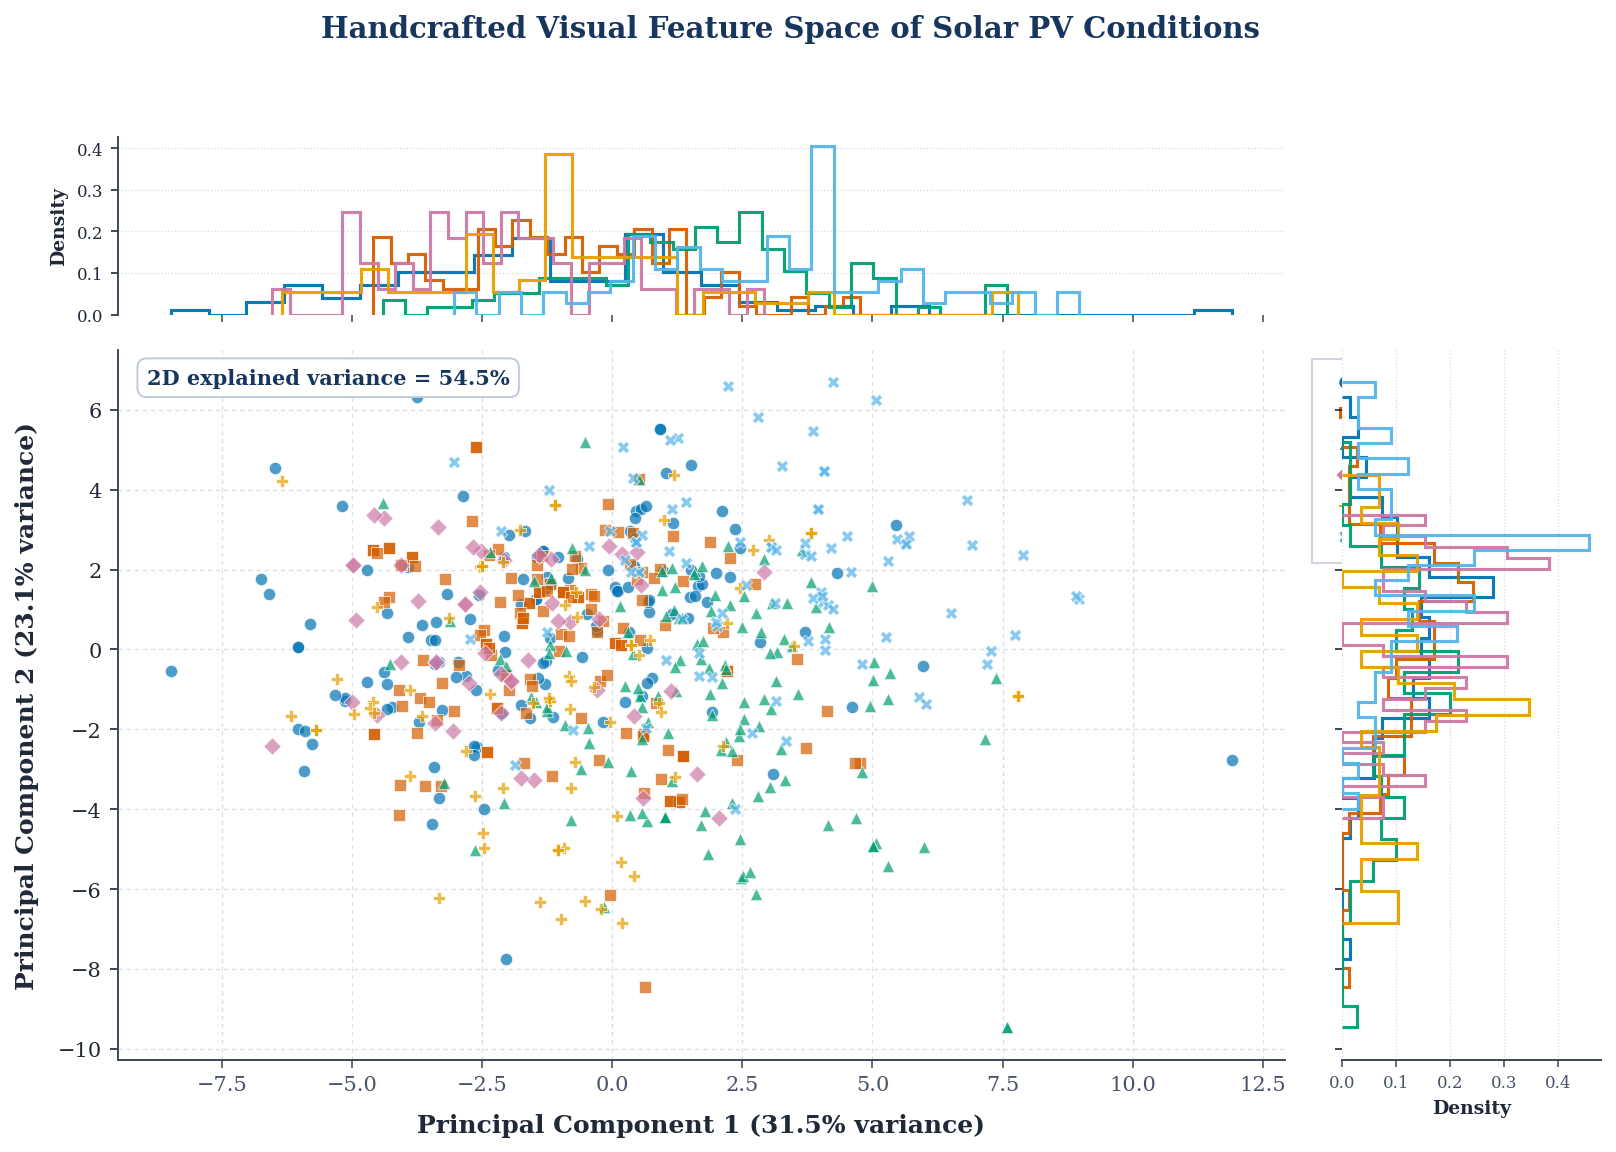

FIGURE 4 — HANDCRAFTED FEATURE SPACE
Training samples        : 619
Number of classes       : 6
PC1 explained variance  : 31.46%
PC2 explained variance  : 23.07%
Combined variance       : 54.52%
PNG and PDF exported successfully.


In [29]:

# =============================================================================
# FIGURE 4 — HANDCRAFTED FEATURE SPACE
# Publication-Ready PCA Visualization with Marginal Distributions
# =============================================================================

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

from matplotlib.lines import Line2D

# =============================================================================
# 1. IEEE-STYLE TYPOGRAPHY
# =============================================================================

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",
        "Times",
        "DejaVu Serif",
        "Nimbus Roman No9 L",
    ],
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 14,
    "legend.fontsize": 9,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# =============================================================================
# 2. VALIDATE EXISTING PCA DATA
# =============================================================================

X_pca = np.asarray(X_train_pca)
y_labels = np.asarray(y_train)

if X_pca.ndim != 2 or X_pca.shape[1] < 2:
    raise ValueError(
        "X_train_pca must contain at least two PCA components."
    )

if len(X_pca) != len(y_labels):
    raise ValueError(
        "X_train_pca and y_train must have equal sample counts."
    )

if not np.isfinite(X_pca[:, :2]).all():
    raise ValueError(
        "The first two PCA components contain NaN or infinite values."
    )

# =============================================================================
# 3. CLASS COLORS AND MARKERS
# =============================================================================

class_palette = [
    "#0072B2",  # Blue
    "#D55E00",  # Vermilion
    "#009E73",  # Green
    "#CC79A7",  # Purple-pink
    "#E69F00",  # Orange
    "#56B4E9",  # Sky blue
]

markers = ["o", "s", "^", "D", "P", "X"]

if len(ordered_classes) > len(class_palette):
    raise ValueError(
        "Extend class_palette to cover all classes in ordered_classes."
    )

# =============================================================================
# 4. FIGURE LAYOUT
# =============================================================================

fig = plt.figure(
    figsize=(11.5, 8.2),
    facecolor="white",
)

grid = fig.add_gridspec(
    2,
    2,
    width_ratios=[4.5, 1.0],
    height_ratios=[1.0, 4.0],
    left=0.11,
    right=0.97,
    bottom=0.11,
    top=0.86,
    wspace=0.08,
    hspace=0.08,
)

ax_top = fig.add_subplot(grid[0, 0])
ax = fig.add_subplot(grid[1, 0], sharex=ax_top)
ax_right = fig.add_subplot(grid[1, 1], sharey=ax)

fig.suptitle(
    "Handcrafted Visual Feature Space of Solar PV Conditions",
    fontsize=14,
    fontweight="bold",
    color="#17365D",
    y=0.96,
)

# =============================================================================
# 5. MAIN PCA SCATTER PLOT
# =============================================================================

legend_handles = []

for class_id, class_name in enumerate(ordered_classes):
    mask = y_labels == class_id

    if not np.any(mask):
        continue

    color = class_palette[class_id]
    marker = markers[class_id % len(markers)]

    points = ax.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        s=35,
        alpha=0.70,
        c=color,
        marker=marker,
        edgecolors="white",
        linewidths=0.45,
        rasterized=True,
        zorder=3,
    )

    legend_handles.append(
        Line2D(
            [0],
            [0],
            marker=marker,
            linestyle="",
            markerfacecolor=color,
            markeredgecolor="white",
            markersize=7,
            label=str(class_name),
        )
    )

ax.set_xlabel(
    f"Principal Component 1 "
    f"({explained_variance[0]:.1f}% variance)",
    fontweight="bold",
    labelpad=9,
)

ax.set_ylabel(
    f"Principal Component 2 "
    f"({explained_variance[1]:.1f}% variance)",
    fontweight="bold",
    labelpad=9,
)

ax.grid(
    True,
    linestyle=(0, (3, 3)),
    linewidth=0.65,
    color="#CBD5E1",
    alpha=0.75,
    zorder=0,
)

ax.set_axisbelow(True)

ax.tick_params(
    direction="out",
    length=4,
    width=0.8,
)

# =============================================================================
# 6. TOP MARGINAL DISTRIBUTIONS
# Uses histograms of the existing PCA coordinates.
# =============================================================================

for class_id, class_name in enumerate(ordered_classes):
    mask = y_labels == class_id

    if not np.any(mask):
        continue

    ax_top.hist(
        X_pca[mask, 0],
        bins=28,
        density=True,
        histtype="step",
        linewidth=1.5,
        color=class_palette[class_id],
        alpha=0.95,
    )

ax_top.set_ylabel(
    "Density",
    fontsize=9,
    fontweight="bold",
)

ax_top.tick_params(
    axis="x",
    labelbottom=False,
)

ax_top.tick_params(
    axis="y",
    labelsize=8,
)

ax_top.grid(
    axis="y",
    linestyle=":",
    linewidth=0.6,
    alpha=0.45,
)

ax_top.spines["bottom"].set_visible(False)

# =============================================================================
# 7. RIGHT MARGINAL DISTRIBUTIONS
# =============================================================================

for class_id, class_name in enumerate(ordered_classes):
    mask = y_labels == class_id

    if not np.any(mask):
        continue

    ax_right.hist(
        X_pca[mask, 1],
        bins=28,
        density=True,
        orientation="horizontal",
        histtype="step",
        linewidth=1.5,
        color=class_palette[class_id],
        alpha=0.95,
    )

ax_right.set_xlabel(
    "Density",
    fontsize=9,
    fontweight="bold",
)

ax_right.tick_params(
    axis="y",
    labelleft=False,
)

ax_right.tick_params(
    axis="x",
    labelsize=8,
)

ax_right.grid(
    axis="x",
    linestyle=":",
    linewidth=0.6,
    alpha=0.45,
)

ax_right.spines["left"].set_visible(False)

# =============================================================================
# 8. LEGEND AND EXPLAINED VARIANCE ANNOTATION
# =============================================================================

ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(1.015, 1.0),
    frameon=True,
    fancybox=False,
    framealpha=0.98,
    edgecolor="#D0D5DD",
    ncol=1,
    borderpad=0.8,
    labelspacing=0.7,
)

total_variance = float(np.sum(explained_variance[:2]))

ax.text(
    0.025,
    0.975,
    f"2D explained variance = {total_variance:.1f}%",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=10,
    fontweight="bold",
    color="#17365D",
    bbox={
        "boxstyle": "round,pad=0.45",
        "facecolor": "white",
        "edgecolor": "#B8C7D9",
        "linewidth": 0.9,
        "alpha": 0.96,
    },
    zorder=5,
)

# =============================================================================
# 9. SAVE PUBLICATION VERSIONS
# =============================================================================

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

fig.savefig(
    FIGURE_DIR / "Figure_4_Handcrafted_Feature_Space.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.15,
    facecolor="white",
)

fig.savefig(
    FIGURE_DIR / "Figure_4_Handcrafted_Feature_Space.pdf",
    bbox_inches="tight",
    pad_inches=0.15,
    facecolor="white",
)

plt.show()
plt.close(fig)

print("=" * 65)
print("FIGURE 4 — HANDCRAFTED FEATURE SPACE")
print("=" * 65)
print(f"Training samples        : {len(y_labels):,}")
print(f"Number of classes       : {len(ordered_classes)}")
print(f"PC1 explained variance  : {explained_variance[0]:.2f}%")
print(f"PC2 explained variance  : {explained_variance[1]:.2f}%")
print(f"Combined variance       : {total_variance:.2f}%")
print("PNG and PDF exported successfully.")

In [30]:
# =============================================================================
# STEP 3.10: UNIVARIATE FEATURE RELEVANCE
# =============================================================================

from sklearn.feature_selection import f_classif

f_values, p_values = f_classif(
    X_train_scaled,
    y_train,
)

feature_importance_df = pd.DataFrame(
    {
        "Feature": FEATURE_COLUMNS,
        "F_Score": f_values,
        "P_Value": p_values,
    }
)

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "F_Score",
        ascending=False,
    )
    .reset_index(drop=True)
)

print("=" * 75)
print("TOP HANDCRAFTED FEATURES")
print("=" * 75)

print(
    feature_importance_df.head(15)
    .to_string(index=False)
)

TOP HANDCRAFTED FEATURES
           Feature   F_Score      P_Value
    brightness_p50 51.564239 1.227926e-44
            S_mean 47.700843 1.095062e-41
            R_mean 44.520066 3.287273e-39
     gradient_mean 41.982806 3.352385e-37
      edge_density 40.348946 6.827787e-36
  glcm_homogeneity 39.869150 1.663426e-35
glcm_dissimilarity 38.554928 1.931092e-34
   brightness_mean 38.330850 2.938761e-34
    brightness_std 37.968891 5.797490e-34
             G_std 37.708580 9.458779e-34
            G_mean 37.642653 1.070850e-33
             B_std 36.269924 1.434203e-32
             R_std 32.364586 2.585216e-29
     glcm_contrast 30.276062 1.529771e-27
             V_std 29.391057 8.753138e-27


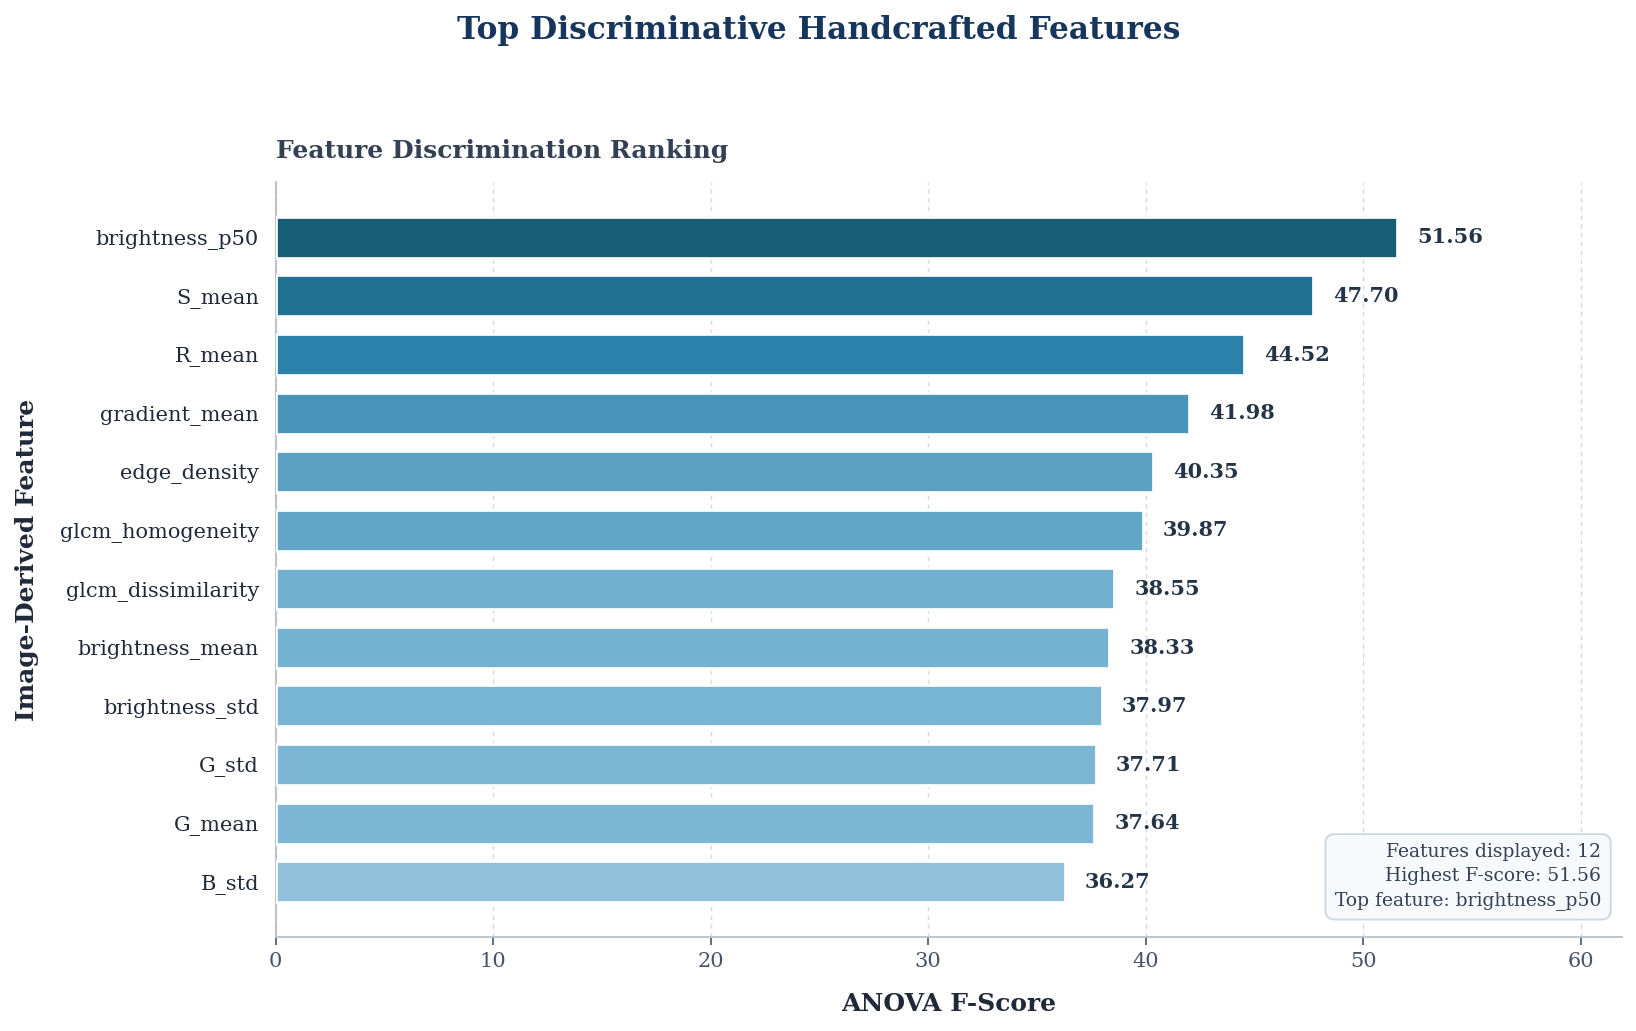

FIGURE 5 — TOP DISCRIMINATIVE HANDCRAFTED FEATURES
           Feature   F_Score
    brightness_p50 51.564239
            S_mean 47.700843
            R_mean 44.520066
     gradient_mean 41.982806
      edge_density 40.348946
  glcm_homogeneity 39.869150
glcm_dissimilarity 38.554928
   brightness_mean 38.330850
    brightness_std 37.968891
             G_std 37.708580
            G_mean 37.642653
             B_std 36.269924

Highest F-score : 51.5642
Top feature     : brightness_p50
PNG             : /content/solar_pv_paper_outputs/figures/Figure_5_Top_Handcrafted_Features.png
PDF             : /content/solar_pv_paper_outputs/figures/Figure_5_Top_Handcrafted_Features.pdf


In [31]:

# =============================================================================
# FIGURE 5 — TOP DISCRIMINATIVE HANDCRAFTED FEATURES
# Publication-Ready IEEE-Style Visualization
# =============================================================================

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# =============================================================================
# 1. PUBLICATION TYPOGRAPHY
# =============================================================================

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",
        "Times",
        "DejaVu Serif",
        "Nimbus Roman No9 L",
    ],
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 14,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# =============================================================================
# 2. PREPARE TOP FEATURES
# Original ranking and F-scores are preserved.
# =============================================================================

top_n = min(12, len(feature_importance_df))

if top_n == 0:
    raise ValueError(
        "feature_importance_df contains no feature records."
    )

top_features = (
    feature_importance_df
    .head(top_n)
    .sort_values("F_Score", ascending=True)
    .copy()
)

feature_names = top_features["Feature"].astype(str).tolist()
f_scores = top_features["F_Score"].to_numpy(dtype=float)

if not np.isfinite(f_scores).all():
    raise ValueError("F_Score contains NaN or infinite values.")

if np.any(f_scores < 0):
    raise ValueError("ANOVA F-scores should be non-negative.")

# =============================================================================
# 3. PROFESSIONAL COLOR GRADIENT
# =============================================================================

custom_cmap = LinearSegmentedColormap.from_list(
    "scientific_blue_teal",
    [
        "#DCEAF5",
        "#78B4D3",
        "#287FA8",
        "#155E75",
    ],
)

score_min = float(f_scores.min())
score_max = float(f_scores.max())

if score_max > score_min:
    normalized_scores = (
        (f_scores - score_min) / (score_max - score_min)
    )
else:
    normalized_scores = np.full(len(f_scores), 0.65)

bar_colors = [
    custom_cmap(0.25 + 0.75 * score)
    for score in normalized_scores
]

# =============================================================================
# 4. FIGURE LAYOUT
# =============================================================================

fig, ax = plt.subplots(
    figsize=(11.5, 7.2),
    facecolor="white",
)

ax.set_facecolor("white")

fig.suptitle(
    "Top Discriminative Handcrafted Features",
    fontsize=15,
    fontweight="bold",
    color="#17365D",
    y=0.97,
)

# =============================================================================
# 5. HORIZONTAL RANKED BAR CHART
# =============================================================================

y_positions = np.arange(len(top_features))

bars = ax.barh(
    y_positions,
    f_scores,
    height=0.70,
    color=bar_colors,
    edgecolor="white",
    linewidth=1.3,
    zorder=3,
)

ax.set_yticks(y_positions)
ax.set_yticklabels(feature_names)

# =============================================================================
# 6. F-SCORE ANNOTATIONS
# =============================================================================

score_range = max(score_max - score_min, abs(score_max), 1.0)
annotation_offset = score_range * 0.018

for bar, score in zip(bars, f_scores):
    ax.text(
        bar.get_width() + annotation_offset,
        bar.get_y() + bar.get_height() / 2,
        f"{score:,.2f}",
        ha="left",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#243447",
        clip_on=False,
    )

# =============================================================================
# 7. AXES AND GRID FORMATTING
# =============================================================================

ax.set_xlabel(
    "ANOVA F-Score",
    fontweight="bold",
    labelpad=10,
)

ax.set_ylabel(
    "Image-Derived Feature",
    fontweight="bold",
    labelpad=10,
)

ax.set_title(
    "Feature Discrimination Ranking",
    loc="left",
    fontsize=12,
    fontweight="bold",
    color="#344054",
    pad=12,
)

ax.set_xlim(
    0,
    max(score_max * 1.20, 1.0),
)

ax.grid(
    axis="x",
    linestyle=(0, (3, 3)),
    linewidth=0.7,
    color="#CBD5E1",
    alpha=0.85,
    zorder=0,
)

ax.set_axisbelow(True)

ax.tick_params(
    axis="y",
    length=0,
    pad=8,
)

ax.tick_params(
    axis="x",
    direction="out",
    length=4,
    width=0.8,
)

ax.spines["left"].set_color("#B8C2CF")
ax.spines["bottom"].set_color("#B8C2CF")

# =============================================================================
# 8. COMPACT STATISTICAL SUMMARY
# =============================================================================

best_idx = int(np.argmax(f_scores))

summary_text = (
    f"Features displayed: {top_n}\n"
    f"Highest F-score: {f_scores[best_idx]:,.2f}\n"
    f"Top feature: {feature_names[best_idx]}"
)

ax.text(
    0.985,
    0.035,
    summary_text,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
    linespacing=1.45,
    color="#344054",
    bbox={
        "boxstyle": "round,pad=0.5",
        "facecolor": "#F7FAFC",
        "edgecolor": "#CBD5E1",
        "linewidth": 0.9,
        "alpha": 0.97,
    },
)

# =============================================================================
# 9. FINAL LAYOUT AND EXPORT
# =============================================================================

fig.tight_layout(rect=[0.02, 0.02, 0.98, 0.93])

png_path = (
    FIGURE_DIR /
    "Figure_5_Top_Handcrafted_Features.png"
)

pdf_path = (
    FIGURE_DIR /
    "Figure_5_Top_Handcrafted_Features.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.15,
    facecolor="white",
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    pad_inches=0.15,
    facecolor="white",
)

plt.show()
plt.close(fig)

# =============================================================================
# 10. REPORT
# =============================================================================

print("=" * 68)
print("FIGURE 5 — TOP DISCRIMINATIVE HANDCRAFTED FEATURES")
print("=" * 68)

print(
    top_features[
        ["Feature", "F_Score"]
    ].sort_values(
        "F_Score",
        ascending=False,
    ).to_string(index=False)
)

print(f"\nHighest F-score : {f_scores[best_idx]:,.4f}")
print(f"Top feature     : {feature_names[best_idx]}")
print(f"PNG             : {png_path}")
print(f"PDF             : {pdf_path}")
print("=" * 68)

In [33]:
%pip install -q catboost lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 5.8 MB/s eta 0:00:00


In [34]:
# =============================================================================
# STEP 4.1 — IMPORT LIBRARIES FOR NEW CLASSIFICATION MODELS
# =============================================================================

import time
import pickle
import warnings
import random

import numpy as np
import pandas as pd

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    matthews_corrcoef,
    log_loss,
)

# New gradient-boosting models
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("=" * 75)
print("NEW CLASSIFICATION MODELS LOADED SUCCESSFULLY")
print("=" * 75)

print("1. CatBoost Classifier")
print("2. LightGBM Classifier")
print("3. HistGradientBoosting Classifier")
print("4. MLP Neural Network")
print("5. K-Nearest Neighbors")
print("=" * 75)

NEW CLASSIFICATION MODELS LOADED SUCCESSFULLY
1. CatBoost Classifier
2. LightGBM Classifier
3. HistGradientBoosting Classifier
4. MLP Neural Network
5. K-Nearest Neighbors


In [35]:
# =============================================================================
# STEP 4.2: CLASS LABEL MAPPING
# =============================================================================

print("=" * 75)
print("CLASS LABEL MAPPING")
print("=" * 75)

for class_name, class_id in sorted(
    class_to_id.items(),
    key=lambda item: item[1],
):
    print(f"{class_id} -> {class_name}")

CLASS LABEL MAPPING
0 -> Clean
1 -> Bird-drop
2 -> Dusty
3 -> Physical-Damage
4 -> Electrical-damage
5 -> Snow-Covered


In [36]:
# =============================================================================
# STEP 4.3: COMMON MODEL EVALUATION FUNCTION
# =============================================================================

def evaluate_classical_model(
    model,
    model_name: str,
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_val: np.ndarray,
    y_val: np.ndarray,
    X_test: np.ndarray,
    y_test: np.ndarray,
    save_dir,
):
    """
    Train and evaluate a classical ML classifier.

    Returns
    -------
    result : dict
        Overall model performance and computational metrics.
    predictions : np.ndarray
        Test-set predicted labels.
    probabilities : np.ndarray or None
        Test-set class probabilities when supported.
    """

    save_dir = Path(save_dir)
    save_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    # -------------------------------------------------------------------------
    # Training
    # -------------------------------------------------------------------------

    train_start = time.perf_counter()

    model.fit(
        X_train,
        y_train,
    )

    train_time = (
        time.perf_counter() -
        train_start
    )

    # -------------------------------------------------------------------------
    # Validation predictions
    # -------------------------------------------------------------------------

    val_predictions = model.predict(
        X_val
    )

    val_accuracy = accuracy_score(
        y_val,
        val_predictions,
    )

    val_macro_f1 = f1_score(
        y_val,
        val_predictions,
        average="macro",
    )

    # -------------------------------------------------------------------------
    # Test inference timing
    # -------------------------------------------------------------------------

    inference_start = time.perf_counter()

    test_predictions = model.predict(
        X_test
    )

    inference_time = (
        time.perf_counter() -
        inference_start
    )

    # -------------------------------------------------------------------------
    # Per-image latency
    # -------------------------------------------------------------------------

    latency_ms = (
        inference_time /
        len(X_test)
        * 1000
    )

    # -------------------------------------------------------------------------
    # Test metrics
    # -------------------------------------------------------------------------

    test_accuracy = accuracy_score(
        y_test,
        test_predictions,
    )

    test_macro_f1 = f1_score(
        y_test,
        test_predictions,
        average="macro",
    )

    test_weighted_f1 = f1_score(
        y_test,
        test_predictions,
        average="weighted",
    )

    test_balanced_accuracy = (
        balanced_accuracy_score(
            y_test,
            test_predictions,
        )
    )

    # -------------------------------------------------------------------------
    # Class probabilities
    # -------------------------------------------------------------------------

    probabilities = None

    if hasattr(
        model,
        "predict_proba",
    ):
        probabilities = model.predict_proba(
            X_test
        )

    # -------------------------------------------------------------------------
    # Model serialization size
    # -------------------------------------------------------------------------

    model_path = (
        save_dir /
        f"{model_name}_model.pkl"
    )

    with open(
        model_path,
        "wb",
    ) as file:

        pickle.dump(
            model,
            file,
            protocol=pickle.HIGHEST_PROTOCOL,
        )

    model_size_mb = (
        model_path.stat().st_size /
        (1024 ** 2)
    )

    # -------------------------------------------------------------------------
    # Result dictionary
    # -------------------------------------------------------------------------

    result = {
        "Model": model_name,
        "Validation_Accuracy": val_accuracy,
        "Validation_Macro_F1": val_macro_f1,
        "Test_Accuracy": test_accuracy,
        "Test_Macro_F1": test_macro_f1,
        "Test_Weighted_F1": test_weighted_f1,
        "Test_Balanced_Accuracy": test_balanced_accuracy,
        "Training_Time_s": train_time,
        "Test_Inference_Time_s": inference_time,
        "Inference_Latency_ms_per_image": latency_ms,
        "Model_Size_MB": model_size_mb,
    }

    return (
        result,
        test_predictions,
        probabilities,
    )

In [40]:
from catboost import CatBoostClassifier

model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="MultiClass",
    random_seed=42,
    verbose=False
)

print("CatBoost initialized successfully.")

CatBoost initialized successfully.


In [41]:
# =============================================================================
# STEP 4.5: CATBOOST CLASSIFIER — TRAINING AND EVALUATION
# =============================================================================

catboost_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="MultiClass",
    random_seed=RANDOM_STATE,
    auto_class_weights="Balanced",
    verbose=False,
    allow_writing_files=False,
    thread_count=-1,
)

(
    catboost_result,
    catboost_predictions,
    catboost_probabilities,
) = evaluate_classical_model(
    model=catboost_model,
    model_name="CatBoost",
    X_train=X_train_scaled,
    y_train=y_train,
    X_val=X_val_scaled,
    y_val=y_val,
    X_test=X_test_scaled,
    y_test=y_test,
    save_dir=RESULT_DIR,
)

print("=" * 75)
print("CATBOOST CLASSIFICATION RESULTS")
print("=" * 75)

for key, value in catboost_result.items():
    if key != "Model":
        print(f"{key:35s}: {value:.6f}")

CATBOOST CLASSIFICATION RESULTS
Validation_Accuracy                : 0.699248
Validation_Macro_F1                : 0.683889
Test_Accuracy                      : 0.676692
Test_Macro_F1                      : 0.613160
Test_Weighted_F1                   : 0.663396
Test_Balanced_Accuracy             : 0.617595
Training_Time_s                    : 22.619177
Test_Inference_Time_s              : 0.001818
Inference_Latency_ms_per_image     : 0.013670
Model_Size_MB                      : 1.766711


In [43]:
# =============================================================================
# STEP 4.5-4.9: TRAIN AND EVALUATE FIVE NEW CLASSIFICATION MODELS
# =============================================================================

import sys
import subprocess
import time
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------------------
# 1. ENSURE REQUIRED LIBRARIES ARE AVAILABLE
# ---------------------------------------------------------------------------

try:
    from catboost import CatBoostClassifier
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "catboost"]
    )
    from catboost import CatBoostClassifier

try:
    from lightgbm import LGBMClassifier
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "lightgbm"]
    )
    from lightgbm import LGBMClassifier

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier

# ---------------------------------------------------------------------------
# 2. INITIALIZE THE FIVE NEW MODELS
# ---------------------------------------------------------------------------

model_specs = [
    (
        "CatBoost",
        "catboost",
        CatBoostClassifier(
            iterations=500,
            depth=6,
            learning_rate=0.05,
            loss_function="MultiClass",
            random_seed=RANDOM_STATE,
            auto_class_weights="Balanced",
            verbose=False,
            allow_writing_files=False,
            thread_count=-1,
        ),
    ),
    (
        "LightGBM",
        "lgbm",
        LGBMClassifier(
            n_estimators=500,
            learning_rate=0.05,
            num_leaves=31,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1,
        ),
    ),
    (
        "HistGradientBoosting",
        "histgb",
        HistGradientBoostingClassifier(
            learning_rate=0.08,
            max_iter=300,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=RANDOM_STATE,
        ),
    ),
    (
        "MLP_Neural_Network",
        "mlp",
        MLPClassifier(
            hidden_layer_sizes=(128, 64),
            activation="relu",
            solver="adam",
            alpha=0.001,
            batch_size=32,
            learning_rate_init=0.001,
            max_iter=300,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=20,
            random_state=RANDOM_STATE,
        ),
    ),
    (
        "KNN",
        "knn",
        KNeighborsClassifier(
            n_neighbors=5,
            weights="distance",
            metric="minkowski",
            p=2,
            n_jobs=-1,
        ),
    ),
]

# ---------------------------------------------------------------------------
# 3. TRAIN AND EVALUATE EACH MODEL
# ---------------------------------------------------------------------------

model_outputs = {}
model_summary = []
failed_models = []

print("=" * 90)
print("SOLAR PANEL CONDITION CLASSIFICATION: NEW MODEL EXPERIMENTS")
print("=" * 90)

for model_name, model_prefix, model in model_specs:

    print(f"\nTraining model: {model_name}")
    print("-" * 90)

    start_time = time.time()

    try:
        (
            model_result,
            model_predictions,
            model_probabilities,
        ) = evaluate_classical_model(
            model=model,
            model_name=model_name,
            X_train=X_train_scaled,
            y_train=y_train,
            X_val=X_val_scaled,
            y_val=y_val,
            X_test=X_test_scaled,
            y_test=y_test,
            save_dir=RESULT_DIR,
        )

        elapsed_time = time.time() - start_time

        # Store all outputs for future analysis and visualization
        model_outputs[model_prefix] = {
            "model": model,
            "result": model_result,
            "predictions": model_predictions,
            "probabilities": model_probabilities,
            "training_evaluation_time_seconds": elapsed_time,
        }

        # Preserve conventional variable names for subsequent notebook cells
        if model_prefix == "catboost":
            catboost_result = model_result
            catboost_predictions = model_predictions
            catboost_probabilities = model_probabilities

        elif model_prefix == "lgbm":
            lgbm_result = model_result
            lgbm_predictions = model_predictions
            lgbm_probabilities = model_probabilities

        elif model_prefix == "histgb":
            histgb_result = model_result
            histgb_predictions = model_predictions
            histgb_probabilities = model_probabilities

        elif model_prefix == "mlp":
            mlp_result = model_result
            mlp_predictions = model_predictions
            mlp_probabilities = model_probabilities

        elif model_prefix == "knn":
            knn_result = model_result
            knn_predictions = model_predictions
            knn_probabilities = model_probabilities

        # Prepare a comparison-table record
        result_record = {"Model": model_name}

        for key, value in model_result.items():
            if key != "Model":
                try:
                    result_record[key] = float(value)
                except (TypeError, ValueError):
                    result_record[key] = value

        result_record["Evaluation_Time_Seconds"] = elapsed_time
        model_summary.append(result_record)

        print(f"Completed: {model_name}")
        print(f"Evaluation time: {elapsed_time:.2f} seconds")

        for key, value in model_result.items():
            if key != "Model":
                try:
                    print(f"{key:35s}: {float(value):.6f}")
                except (TypeError, ValueError):
                    print(f"{key:35s}: {value}")

    except Exception as exc:
        failed_models.append(
            {
                "Model": model_name,
                "Error": str(exc),
            }
        )

        print(f"FAILED: {model_name}")
        print(f"Error type: {type(exc).__name__}")
        print(f"Error details: {exc}")

# ---------------------------------------------------------------------------
# 4. CREATE THE MODEL COMPARISON TABLE
# ---------------------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL MODEL COMPARISON")
print("=" * 90)

if model_summary:
    model_comparison_df = pd.DataFrame(model_summary)

    preferred_metrics = [
        "Model",
        "Accuracy",
        "Balanced_Accuracy",
        "Precision",
        "Recall",
        "F1",
        "MCC",
        "ROC_AUC",
        "Evaluation_Time_Seconds",
    ]

    # Match existing metric names without assuming every metric is available
    available_columns = [
        col for col in preferred_metrics
        if col in model_comparison_df.columns
    ]

    remaining_columns = [
        col for col in model_comparison_df.columns
        if col not in available_columns
    ]

    model_comparison_df = model_comparison_df[
        available_columns + remaining_columns
    ]

    display(model_comparison_df)

    # Save the actual results for the research paper
    comparison_csv_path = RESULT_DIR / "New_Model_Comparison.csv"

    model_comparison_df.to_csv(
        comparison_csv_path,
        index=False,
    )

    print(f"\nComparison table saved to: {comparison_csv_path}")

else:
    print("No models completed successfully. Review the errors above.")

# ---------------------------------------------------------------------------
# 5. REPORT FAILED MODELS, IF ANY
# ---------------------------------------------------------------------------

if failed_models:
    print("\n" + "=" * 90)
    print("MODELS REQUIRING ATTENTION")
    print("=" * 90)

    display(pd.DataFrame(failed_models))

print("\n" + "=" * 90)
print("EXPERIMENT FINISHED")
print(f"Successful models: {len(model_outputs)} / {len(model_specs)}")
print(f"Failed models: {len(failed_models)}")
print(f"Output directory: {RESULT_DIR}")
print("=" * 90)

SOLAR PANEL CONDITION CLASSIFICATION: NEW MODEL EXPERIMENTS

Training model: CatBoost
------------------------------------------------------------------------------------------
Completed: CatBoost
Evaluation time: 24.22 seconds
Validation_Accuracy                : 0.699248
Validation_Macro_F1                : 0.683889
Test_Accuracy                      : 0.676692
Test_Macro_F1                      : 0.613160
Test_Weighted_F1                   : 0.663396
Test_Balanced_Accuracy             : 0.617595
Training_Time_s                    : 24.196807
Test_Inference_Time_s              : 0.001580
Inference_Latency_ms_per_image     : 0.011878
Model_Size_MB                      : 1.766711

Training model: LightGBM
------------------------------------------------------------------------------------------
Completed: LightGBM
Evaluation time: 3.05 seconds
Validation_Accuracy                : 0.676692
Validation_Macro_F1                : 0.643804
Test_Accuracy                      : 0.699248
Test_M

,Model,Evaluation_Time_Seconds,Validation_Accuracy,Validation_Macro_F1,Test_Accuracy,Test_Macro_F1,Test_Weighted_F1,Test_Balanced_Accuracy,Training_Time_s,Test_Inference_Time_s,Inference_Latency_ms_per_image,Model_Size_MB
0,CatBoost,24.217180,0.699248,0.683889,0.676692,0.613160,0.663396,0.617595,24.196807,0.001580,0.011878,1.766711
1,LightGBM,3.045867,0.676692,0.643804,0.699248,0.636477,0.682295,0.632613,2.701388,0.022256,0.167337,5.345734
2,HistGradientBoosting,3.851022,0.676692,0.666271,0.714286,0.632724,0.688574,0.641548,3.319652,0.038380,0.288569,3.075088
3,MLP_Neural_Network,1.134652,0.714286,0.699697,0.631579,0.547304,0.605167,0.562979,1.119970,0.000760,0.005712,0.294215
4,KNN,0.113713,0.676692,0.655110,0.661654,0.605927,0.646883,0.608444,0.002138,0.006702,0.050392,0.142323



Comparison table saved to: /content/solar_pv_paper_outputs/results/New_Model_Comparison.csv

EXPERIMENT FINISHED
Successful models: 5 / 5
Failed models: 0
Output directory: /content/solar_pv_paper_outputs/results


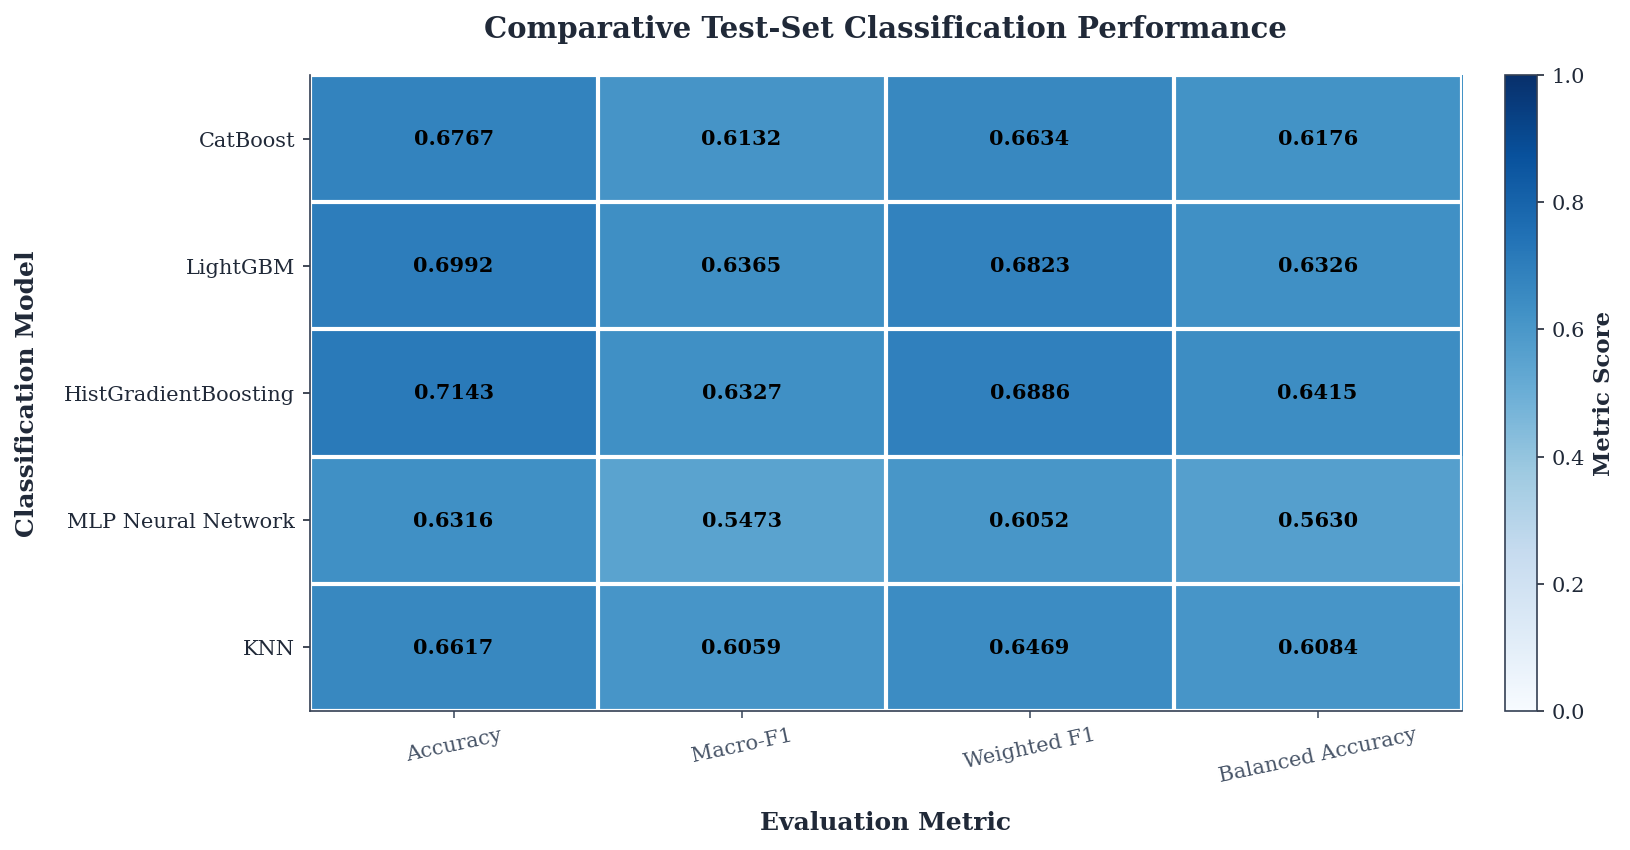

Figure 1 generated successfully.
PNG: /content/solar_pv_paper_outputs/results/figures/Figure_1_Multimetric_Performance_Heatmap.png
PDF: /content/solar_pv_paper_outputs/results/figures/Figure_1_Multimetric_Performance_Heatmap.pdf


In [47]:
# =============================================================================
# FIGURE 1 — MULTIMETRIC MODEL PERFORMANCE HEATMAP
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# ---------------------------------------------------------------------------

FIGURE_DIR = Path(RESULT_DIR) / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------------
# 2. PUBLICATION-QUALITY FORMATTING
# ---------------------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "bold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ---------------------------------------------------------------------------
# 3. EXTRACT ACTUAL MODEL RESULTS
# ---------------------------------------------------------------------------

model_order = [
    ("catboost", "CatBoost"),
    ("lgbm", "LightGBM"),
    ("histgb", "HistGradientBoosting"),
    ("mlp", "MLP Neural Network"),
    ("knn", "KNN"),
]

metric_columns = [
    ("Accuracy", "Test_Accuracy"),
    ("Macro-F1", "Test_Macro_F1"),
    ("Weighted F1", "Test_Weighted_F1"),
    ("Balanced Accuracy", "Test_Balanced_Accuracy"),
]

available_models = [
    (key, label)
    for key, label in model_order
    if key in model_outputs
    and model_outputs[key].get("result") is not None
]

if not available_models:
    raise ValueError(
        "No evaluated model results found. Run the model evaluation cell first."
    )

scores = []

for model_key, model_label in available_models:
    result = model_outputs[model_key]["result"]
    row = []

    for metric_label, metric_key in metric_columns:
        value = result.get(metric_key, np.nan)

        try:
            value = float(value)
        except (TypeError, ValueError):
            value = np.nan

        if not np.isfinite(value):
            value = np.nan

        row.append(value)

    scores.append(row)

performance_df = pd.DataFrame(
    scores,
    index=[label for _, label in available_models],
    columns=[label for label, _ in metric_columns],
)

# ---------------------------------------------------------------------------
# 4. CREATE HEATMAP
# ---------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 5.8))

masked_scores = np.ma.masked_invalid(
    performance_df.to_numpy(dtype=float)
)

im = ax.imshow(
    masked_scores,
    cmap="Blues",
    vmin=0,
    vmax=1,
    aspect="auto",
)

ax.set_xticks(
    np.arange(len(performance_df.columns)),
    labels=performance_df.columns,
)

ax.set_yticks(
    np.arange(len(performance_df.index)),
    labels=performance_df.index,
)

ax.tick_params(axis="x", rotation=12)

# Annotate actual metric values
for i in range(performance_df.shape[0]):
    for j in range(performance_df.shape[1]):

        value = performance_df.iloc[i, j]

        annotation = (
            f"{value:.4f}"
            if pd.notna(value)
            else "N/A"
        )

        ax.text(
            j,
            i,
            annotation,
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="black",
        )

ax.set_title(
    "Comparative Test-Set Classification Performance",
    pad=18,
)

ax.set_xlabel("Evaluation Metric", labelpad=12)
ax.set_ylabel("Classification Model", labelpad=12)

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.035,
    pad=0.035,
)

cbar.set_label(
    "Metric Score",
    fontsize=11,
    fontweight="bold",
)

ax.set_xticks(
    np.arange(-0.5, len(performance_df.columns), 1),
    minor=True,
)

ax.set_yticks(
    np.arange(-0.5, len(performance_df.index), 1),
    minor=True,
)

ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=2,
)

ax.tick_params(which="minor", bottom=False, left=False)

fig.tight_layout()

# ---------------------------------------------------------------------------
# 5. SAVE AND DISPLAY
# ---------------------------------------------------------------------------

png_path = FIGURE_DIR / "Figure_1_Multimetric_Performance_Heatmap.png"
pdf_path = FIGURE_DIR / "Figure_1_Multimetric_Performance_Heatmap.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

print("Figure 1 generated successfully.")
print(f"PNG: {png_path}")
print(f"PDF: {pdf_path}")

plt.close(fig)

FIGURE 2: CLASS-WISE RECALL HEATMAP

Class labels:
  0 -> Class 0
  1 -> Class 1
  2 -> Class 2
  3 -> Class 3
  4 -> Class 4
  5 -> Class 5

Models included:
  - CatBoost
  - LightGBM
  - HistGradientBoosting
  - MLP Neural Network
  - KNN

Class-wise recall values:


,CatBoost,LightGBM,HistGradientBoosting,MLP Neural Network,KNN
Class 0,0.7586,0.8276,0.8276,0.6207,0.6207
Class 1,0.7097,0.7419,0.7742,0.7097,0.9032
Class 2,0.7241,0.7241,0.7586,0.7586,0.6207
Class 3,0.0909,0.0909,0.0000,0.0000,0.2727
Class 4,0.5333,0.4667,0.6000,0.4000,0.4000
Class 5,0.8889,0.9444,0.8889,0.8889,0.8333


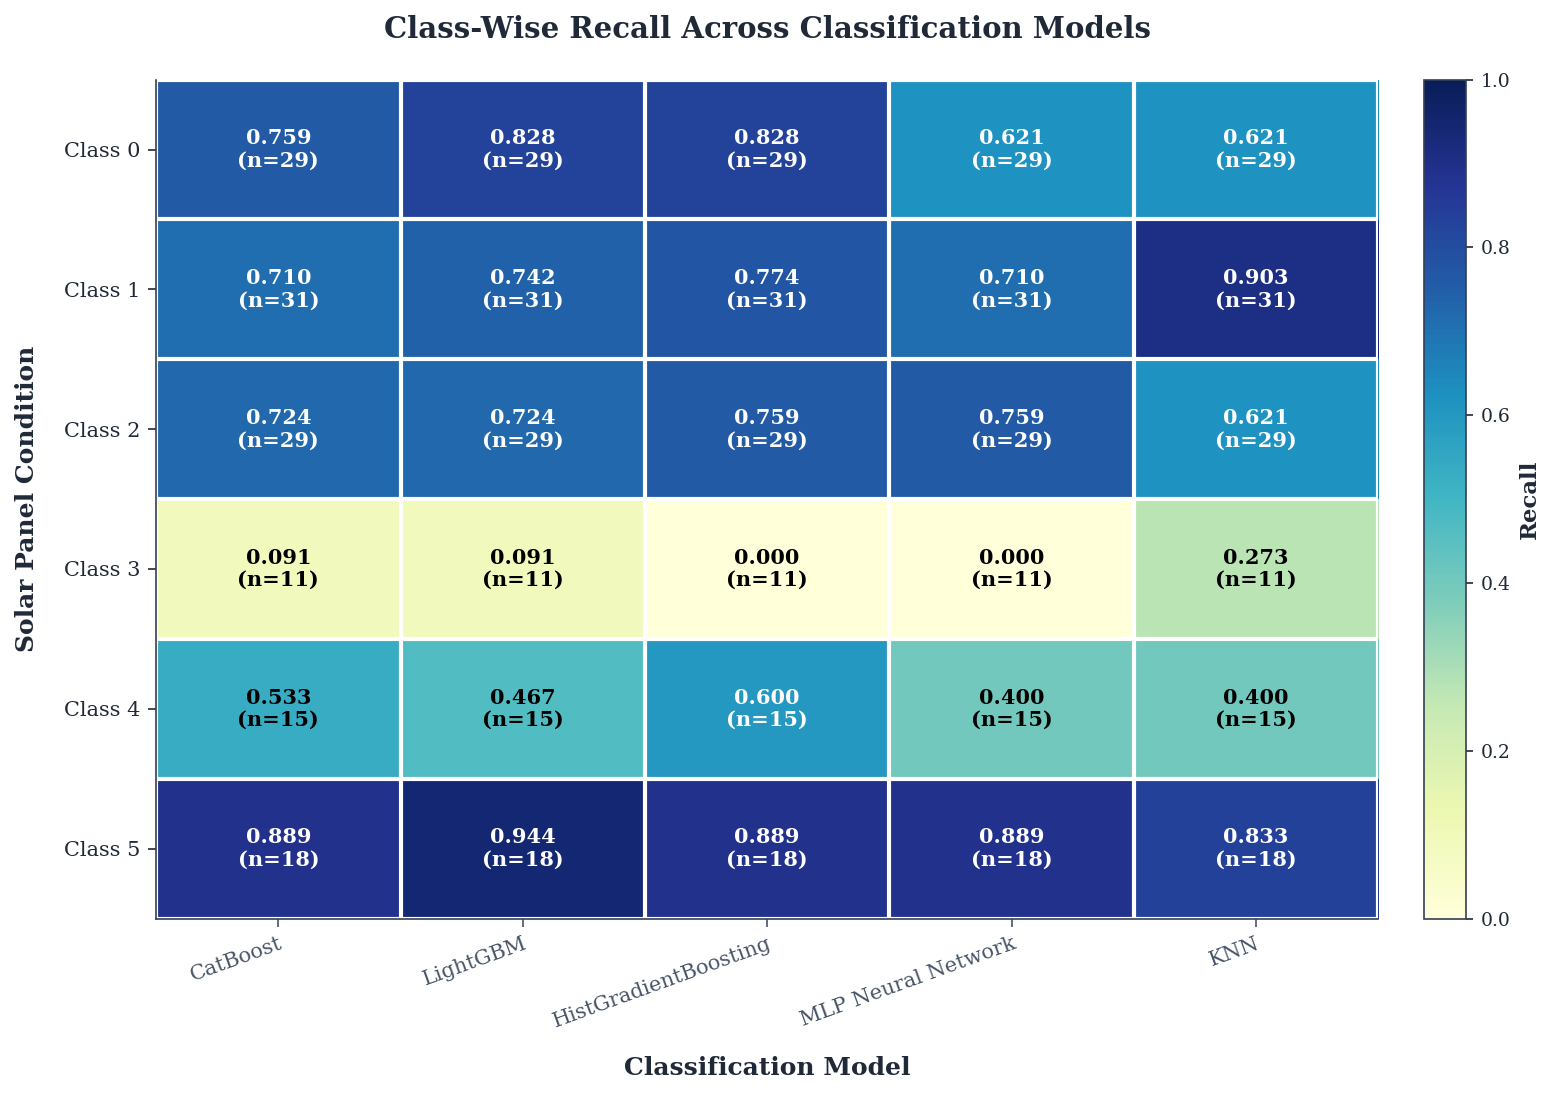


FIGURE 2 GENERATED SUCCESSFULLY
PNG file: /content/solar_pv_paper_outputs/results/figures/Figure_2_Per_Class_Recall_Heatmap.png
PDF file: /content/solar_pv_paper_outputs/results/figures/Figure_2_Per_Class_Recall_Heatmap.pdf

Text contrast is selected automatically for every heatmap cell.
Light cells use dark text; dark cells use light text.
The figure shows actual test-set recall and class support.


In [49]:
# =============================================================================
# FIGURE 2 — CLASS-WISE RECALL HEATMAP
# Solar Panel Condition Classification
# IEEE Publication-Quality Visualization
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import confusion_matrix


# =============================================================================
# 1. VALIDATE EXISTING RESULTS
# =============================================================================

if "model_outputs" not in globals():
    raise NameError(
        "model_outputs is missing. Run the model evaluation cell first."
    )

if "y_test" not in globals():
    raise NameError(
        "y_test is missing. Run the data-splitting cell first."
    )

if "RESULT_DIR" not in globals():
    raise NameError(
        "RESULT_DIR is missing. Run the setup cell first."
    )

FIGURE_DIR = Path(RESULT_DIR) / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# =============================================================================
# 2. PUBLICATION-QUALITY FORMATTING
# =============================================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "bold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# =============================================================================
# 3. PREPARE TEST LABELS AND MODELS
# =============================================================================

y_true = np.asarray(
    y_test.to_numpy() if hasattr(y_test, "to_numpy") else y_test
).reshape(-1)

class_values = np.unique(y_true)
n_classes = len(class_values)

model_order = [
    ("catboost", "CatBoost"),
    ("lgbm", "LightGBM"),
    ("histgb", "HistGradientBoosting"),
    ("mlp", "MLP Neural Network"),
    ("knn", "KNN"),
]

available_models = [
    (key, label)
    for key, label in model_order
    if key in model_outputs
    and model_outputs[key].get("predictions") is not None
]

if not available_models:
    raise ValueError(
        "No stored predictions were found in model_outputs."
    )


# =============================================================================
# 4. RESOLVE CLASS NAMES
# =============================================================================

# If labels are encoded numerically, you may define CLASS_NAMES_OVERRIDE
# before running this cell. The list must match the actual encoding order.
#
# Example, ONLY if this is your confirmed label encoding:
#
# CLASS_NAMES_OVERRIDE = [
#     "Bird-drop",
#     "Clean",
#     "Dusty",
#     "Electrical-damage",
#     "Physical-Damage",
#     "Snow-Covered",
# ]

class_names = None

if "CLASS_NAMES_OVERRIDE" in globals():

    class_names = list(CLASS_NAMES_OVERRIDE)

    if len(class_names) != n_classes:
        raise ValueError(
            "CLASS_NAMES_OVERRIDE must contain exactly "
            f"{n_classes} class names."
        )

# Try to recover original names from an existing label encoder.
if class_names is None:

    for encoder_name in [
        "label_encoder",
        "le",
        "target_encoder",
        "class_encoder",
    ]:

        encoder = globals().get(encoder_name)

        if encoder is None or not hasattr(encoder, "classes_"):
            continue

        encoder_classes = np.asarray(encoder.classes_)

        try:
            encoded_values = np.asarray(class_values, dtype=int)

            if (
                len(encoder_classes) == n_classes
                and np.array_equal(
                    encoded_values,
                    np.arange(n_classes),
                )
            ):
                class_names = [
                    str(encoder_classes[index])
                    for index in encoded_values
                ]
                break

        except (TypeError, ValueError):
            continue

# Preserve string labels where they are already the original class names.
if class_names is None:

    if not np.issubdtype(class_values.dtype, np.number):
        class_names = [
            str(value)
            for value in class_values
        ]
    else:
        class_names = [
            f"Class {value}"
            for value in class_values
        ]

print("=" * 80)
print("FIGURE 2: CLASS-WISE RECALL HEATMAP")
print("=" * 80)

print("\nClass labels:")
for class_value, class_name in zip(class_values, class_names):
    print(f"  {class_value} -> {class_name}")

print("\nModels included:")
for _, model_label in available_models:
    print(f"  - {model_label}")


# =============================================================================
# 5. COMPUTE CLASS-WISE RECALL
# =============================================================================

recall_matrix = np.full(
    (n_classes, len(available_models)),
    np.nan,
)

support_matrix = np.zeros(
    (n_classes, len(available_models)),
    dtype=int,
)

for model_index, (model_key, model_label) in enumerate(available_models):

    predictions = model_outputs[model_key]["predictions"]

    if hasattr(predictions, "to_numpy"):
        predictions = predictions.to_numpy()

    predictions = np.asarray(predictions).reshape(-1)

    if len(predictions) != len(y_true):
        raise ValueError(
            f"{model_label}: number of predictions "
            "does not match the number of test labels."
        )

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=class_values,
    )

    # Support = number of actual test samples in each class.
    class_support = cm.sum(axis=1)

    # Recall = correctly classified samples / actual samples.
    class_recall = np.divide(
        np.diag(cm),
        class_support,
        out=np.full(n_classes, np.nan),
        where=class_support > 0,
    )

    recall_matrix[:, model_index] = class_recall
    support_matrix[:, model_index] = class_support


# Create a numerical table for inspection and reuse.
recall_df = pd.DataFrame(
    recall_matrix,
    index=class_names,
    columns=[label for _, label in available_models],
)

support_df = pd.DataFrame(
    support_matrix,
    index=class_names,
    columns=[label for _, label in available_models],
)

print("\nClass-wise recall values:")
display(recall_df.round(4))


# =============================================================================
# 6. CREATE HEATMAP
# =============================================================================

fig_width = max(
    10.5,
    1.7 * len(available_models),
)

fig_height = max(
    6.0,
    0.9 * n_classes + 2,
)

fig, ax = plt.subplots(
    figsize=(fig_width, fig_height),
)

heatmap_cmap = plt.get_cmap("YlGnBu")

im = ax.imshow(
    np.ma.masked_invalid(recall_matrix),
    cmap=heatmap_cmap,
    vmin=0,
    vmax=1,
    aspect="auto",
    interpolation="nearest",
)


# =============================================================================
# 7. AXIS LABELS
# =============================================================================

ax.set_xticks(
    np.arange(len(available_models)),
)

ax.set_xticklabels(
    [label for _, label in available_models],
    rotation=20,
    ha="right",
    rotation_mode="anchor",
)

ax.set_yticks(
    np.arange(n_classes),
)

ax.set_yticklabels(
    class_names,
)


# =============================================================================
# 8. ANNOTATIONS WITH AUTOMATIC TEXT CONTRAST
# =============================================================================

def get_contrast_text_color(value, cmap, norm):
    """
    Select black or white based on the actual heatmap-cell luminance.

    Light backgrounds receive black text.
    Dark backgrounds receive white text.
    """

    rgba = cmap(norm(value))

    red, green, blue = rgba[:3]

    luminance = (
        0.2126 * red
        + 0.7152 * green
        + 0.0722 * blue
    )

    return "black" if luminance >= 0.55 else "white"


for row in range(n_classes):

    for col in range(len(available_models)):

        value = recall_matrix[row, col]
        support = support_matrix[row, col]

        if np.isfinite(value):

            annotation = (
                f"{value:.3f}\n"
                f"(n={support})"
            )

            # Main correction: calculate text colour from cell brightness.
            annotation_color = get_contrast_text_color(
                value,
                heatmap_cmap,
                im.norm,
            )

        else:

            annotation = f"N/A\n(n={support})"
            annotation_color = "black"

        ax.text(
            col,
            row,
            annotation,
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
            color=annotation_color,
            linespacing=1.15,
        )


# =============================================================================
# 9. GRIDLINES AND AXIS STYLING
# =============================================================================

ax.set_xticks(
    np.arange(-0.5, len(available_models), 1),
    minor=True,
)

ax.set_yticks(
    np.arange(-0.5, n_classes, 1),
    minor=True,
)

ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=2,
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False,
)

ax.tick_params(
    axis="both",
    which="major",
    length=4,
    width=0.8,
)

ax.set_xlabel(
    "Classification Model",
    labelpad=12,
)

ax.set_ylabel(
    "Solar Panel Condition",
    labelpad=12,
)

ax.set_title(
    "Class-Wise Recall Across Classification Models",
    pad=20,
    fontweight="bold",
)


# =============================================================================
# 10. COLORBAR
# =============================================================================

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.035,
    pad=0.035,
)

cbar.set_label(
    "Recall",
    fontsize=11,
    fontweight="bold",
)

cbar.set_ticks(
    np.linspace(0, 1, 6),
)

cbar.ax.tick_params(
    labelsize=9,
)


# =============================================================================
# 11. LAYOUT
# =============================================================================

fig.tight_layout()


# =============================================================================
# 12. SAVE PNG AND PDF
# =============================================================================

png_path = (
    FIGURE_DIR
    / "Figure_2_Per_Class_Recall_Heatmap.png"
)

pdf_path = (
    FIGURE_DIR
    / "Figure_2_Per_Class_Recall_Heatmap.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white",
)


# =============================================================================
# 13. DISPLAY FIGURE
# =============================================================================

plt.show()
plt.close(fig)


# =============================================================================
# 14. COMPLETION SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("FIGURE 2 GENERATED SUCCESSFULLY")
print("=" * 80)

print(f"PNG file: {png_path}")
print(f"PDF file: {pdf_path}")

print("\nText contrast is selected automatically for every heatmap cell.")
print("Light cells use dark text; dark cells use light text.")
print("The figure shows actual test-set recall and class support.")
print("=" * 80)

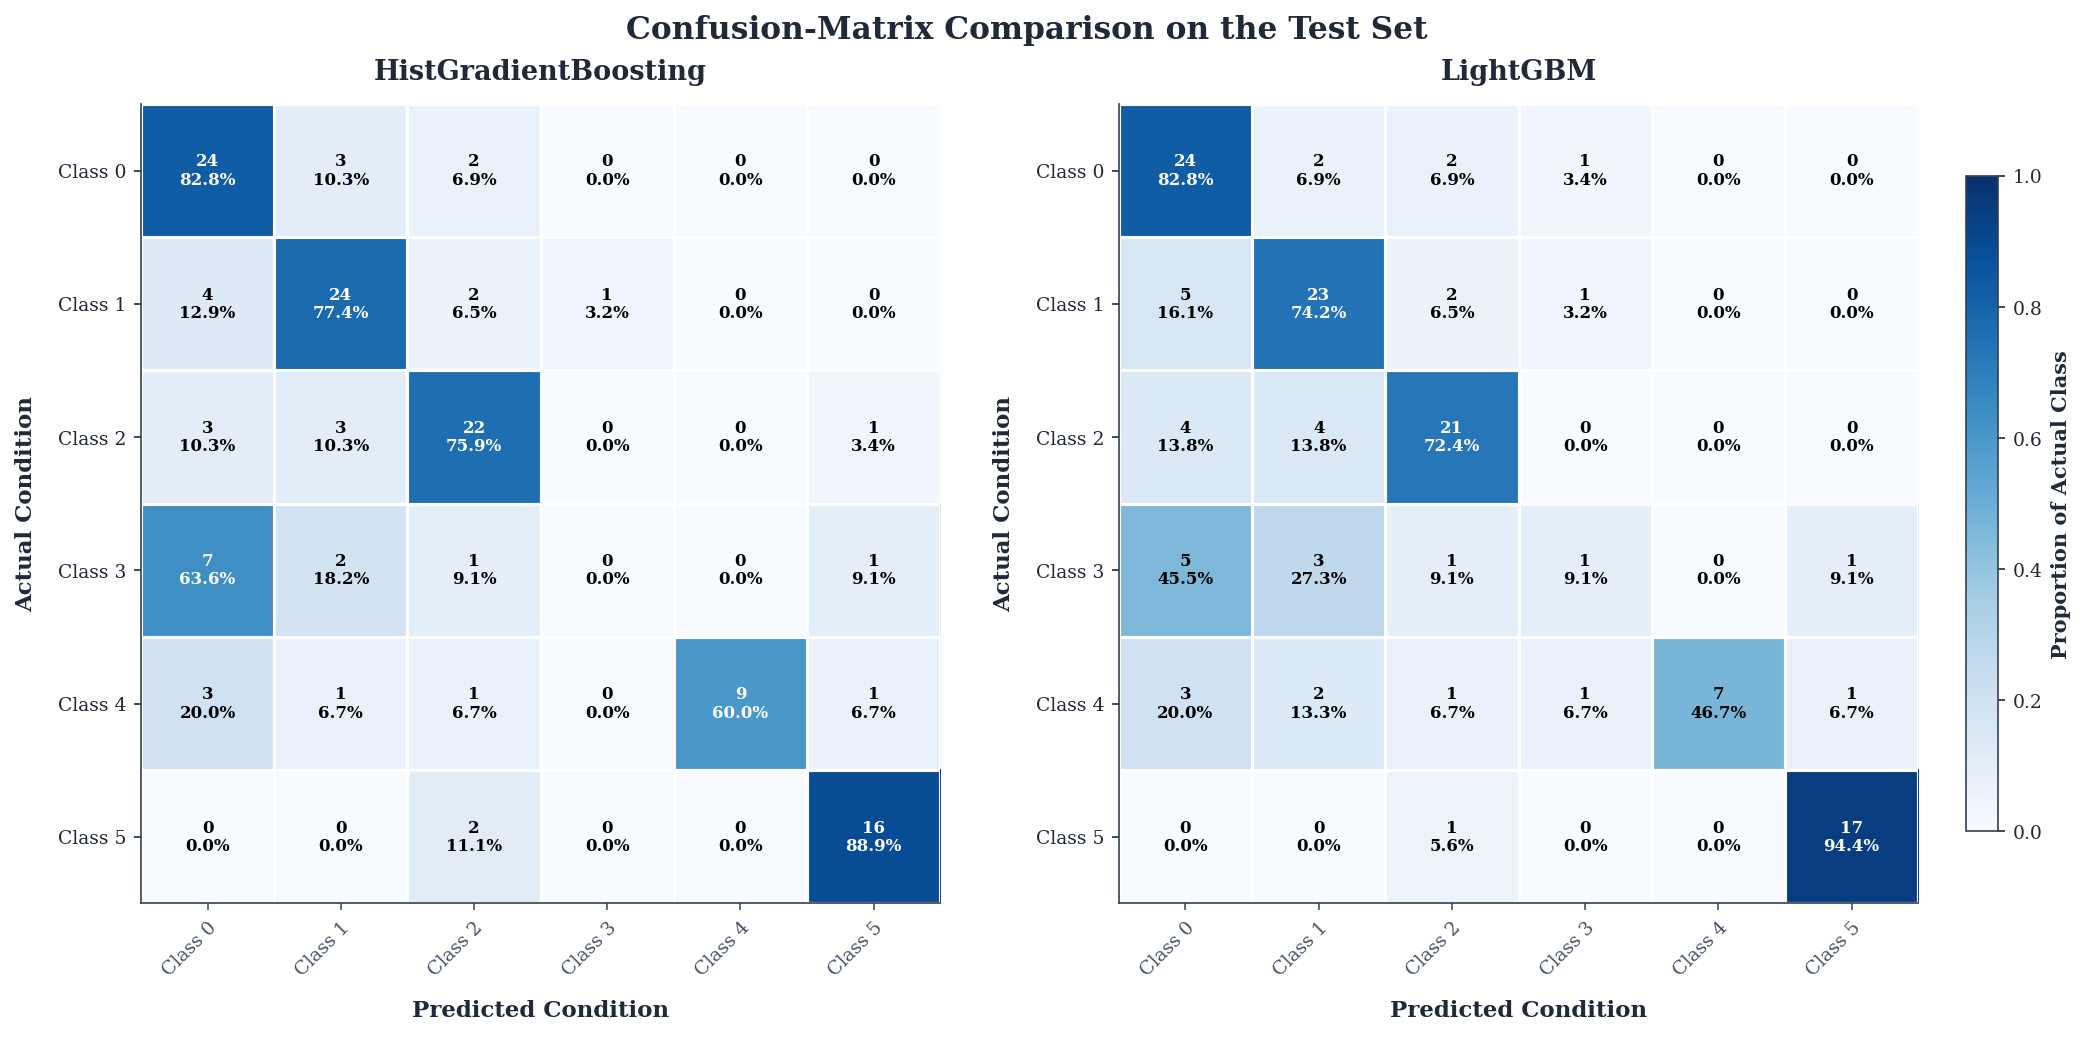

FIGURE 3 GENERATED SUCCESSFULLY
PNG: /content/solar_pv_paper_outputs/results/figures/Figure_3_Confusion_Matrix_Comparison.png
PDF: /content/solar_pv_paper_outputs/results/figures/Figure_3_Confusion_Matrix_Comparison.pdf

Annotation format:
First line  = number of test samples
Second line = proportion of the actual class

HistGradientBoosting test confusion matrix:
[[24  3  2  0  0  0]
 [ 4 24  2  1  0  0]
 [ 3  3 22  0  0  1]
 [ 7  2  1  0  0  1]
 [ 3  1  1  0  9  1]
 [ 0  0  2  0  0 16]]

LightGBM test confusion matrix:
[[24  2  2  1  0  0]
 [ 5 23  2  1  0  0]
 [ 4  4 21  0  0  0]
 [ 5  3  1  1  0  1]
 [ 3  2  1  1  7  1]
 [ 0  0  1  0  0 17]]


In [50]:
# =============================================================================
# FIGURE 3 — CONFUSION-MATRIX COMPARISON
# HistGradientBoosting vs LightGBM
# IEEE Publication-Quality Visualization
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import confusion_matrix


# =============================================================================
# 1. VALIDATE INPUTS
# =============================================================================

if "model_outputs" not in globals():
    raise NameError("Run the model evaluation cell first.")

if "y_test" not in globals():
    raise NameError("y_test is not available.")

if "RESULT_DIR" not in globals():
    raise NameError("RESULT_DIR is not available.")

required_models = ["histgb", "lgbm"]

for model_key in required_models:
    if (
        model_key not in model_outputs
        or model_outputs[model_key].get("predictions") is None
    ):
        raise ValueError(
            f"Predictions for {model_key} are missing. "
            "Run the corresponding model evaluation first."
        )

FIGURE_DIR = Path(RESULT_DIR) / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# =============================================================================
# 2. PUBLICATION FORMATTING
# =============================================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.labelweight": "bold",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# =============================================================================
# 3. PREPARE GROUND-TRUTH LABELS
# =============================================================================

y_true = np.asarray(
    y_test.to_numpy() if hasattr(y_test, "to_numpy") else y_test
).reshape(-1)

class_values = np.unique(y_true)
n_classes = len(class_values)


# =============================================================================
# 4. RESOLVE CLASS NAMES
# =============================================================================

class_names = None

# Explicit class-name mapping, if already defined and verified
if "CLASS_NAMES_OVERRIDE" in globals():
    class_names = list(CLASS_NAMES_OVERRIDE)

    if len(class_names) != n_classes:
        raise ValueError(
            "CLASS_NAMES_OVERRIDE must contain exactly "
            f"{n_classes} class names."
        )

# Attempt to recover original names from an existing fitted encoder
if class_names is None:
    for encoder_name in [
        "label_encoder",
        "le",
        "target_encoder",
        "class_encoder",
    ]:
        encoder = globals().get(encoder_name)

        if encoder is None or not hasattr(encoder, "classes_"):
            continue

        encoder_classes = np.asarray(encoder.classes_)

        try:
            encoded_values = np.asarray(class_values, dtype=int)

            if (
                len(encoder_classes) == n_classes
                and np.array_equal(
                    encoded_values,
                    np.arange(n_classes),
                )
            ):
                class_names = [
                    str(encoder_classes[index])
                    for index in encoded_values
                ]
                break

        except (TypeError, ValueError):
            continue

# Preserve original textual labels when possible
if class_names is None:
    if not np.issubdtype(class_values.dtype, np.number):
        class_names = [str(value) for value in class_values]
    else:
        class_names = [f"Class {value}" for value in class_values]


# =============================================================================
# 5. RETRIEVE TEST PREDICTIONS
# =============================================================================

def get_test_predictions(model_key):
    """Return stored predictions as a one-dimensional NumPy array."""

    predictions = model_outputs[model_key]["predictions"]

    if hasattr(predictions, "to_numpy"):
        predictions = predictions.to_numpy()

    predictions = np.asarray(predictions).reshape(-1)

    if len(predictions) != len(y_true):
        raise ValueError(
            f"{model_key}: prediction count does not match test-set size."
        )

    return predictions


histgb_predictions = get_test_predictions("histgb")
lgbm_predictions = get_test_predictions("lgbm")


# =============================================================================
# 6. COMPUTE CONFUSION MATRICES
# =============================================================================

histgb_cm = confusion_matrix(
    y_true,
    histgb_predictions,
    labels=class_values,
)

lgbm_cm = confusion_matrix(
    y_true,
    lgbm_predictions,
    labels=class_values,
)


def normalize_confusion_matrix(cm):
    """Normalize each row by the number of actual samples in that class."""

    row_totals = cm.sum(axis=1, keepdims=True)

    return np.divide(
        cm,
        row_totals,
        out=np.zeros_like(cm, dtype=float),
        where=row_totals > 0,
    )


histgb_cm_normalized = normalize_confusion_matrix(histgb_cm)
lgbm_cm_normalized = normalize_confusion_matrix(lgbm_cm)


# =============================================================================
# 7. AUTOMATIC ANNOTATION CONTRAST
# =============================================================================

def annotation_color(value, cmap, norm):
    """Select text color using the actual heatmap-cell luminance."""

    red, green, blue, _ = cmap(norm(value))

    luminance = (
        0.2126 * red
        + 0.7152 * green
        + 0.0722 * blue
    )

    return "black" if luminance >= 0.55 else "white"


# =============================================================================
# 8. CREATE SIDE-BY-SIDE CONFUSION MATRICES
# =============================================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6.8),
    constrained_layout=True,
)

cmap = plt.get_cmap("Blues")
image_handles = []

confusion_results = [
    (
        axes[0],
        histgb_cm,
        histgb_cm_normalized,
        "HistGradientBoosting",
    ),
    (
        axes[1],
        lgbm_cm,
        lgbm_cm_normalized,
        "LightGBM",
    ),
]

for ax, cm, cm_normalized, model_name in confusion_results:

    image_handle = ax.imshow(
        cm_normalized,
        cmap=cmap,
        vmin=0,
        vmax=1,
        interpolation="nearest",
        aspect="equal",
    )

    image_handles.append(image_handle)

    ax.set_title(
        model_name,
        pad=12,
        fontweight="bold",
    )

    ax.set_xlabel("Predicted Condition", labelpad=10)
    ax.set_ylabel("Actual Condition", labelpad=10)

    ax.set_xticks(np.arange(n_classes))
    ax.set_xticklabels(
        class_names,
        rotation=45,
        ha="right",
        rotation_mode="anchor",
    )

    ax.set_yticks(np.arange(n_classes))
    ax.set_yticklabels(class_names)

    # Annotate raw count and row-normalized percentage
    for row in range(n_classes):
        for col in range(n_classes):

            count = cm[row, col]
            percentage = cm_normalized[row, col]

            text_color = annotation_color(
                percentage,
                cmap,
                image_handle.norm,
            )

            ax.text(
                col,
                row,
                f"{count}\n{percentage:.1%}",
                ha="center",
                va="center",
                fontsize=8,
                fontweight="bold",
                color=text_color,
                linespacing=1.1,
            )

    # White separators between cells
    ax.set_xticks(
        np.arange(-0.5, n_classes, 1),
        minor=True,
    )

    ax.set_yticks(
        np.arange(-0.5, n_classes, 1),
        minor=True,
    )

    ax.grid(
        which="minor",
        color="white",
        linestyle="-",
        linewidth=1.5,
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False,
    )

fig.suptitle(
    "Confusion-Matrix Comparison on the Test Set",
    fontsize=15,
    fontweight="bold",
)


# =============================================================================
# 9. SHARED COLORBAR
# =============================================================================

colorbar = fig.colorbar(
    image_handles[1],
    ax=axes,
    shrink=0.82,
    pad=0.025,
)

colorbar.set_label(
    "Proportion of Actual Class",
    fontsize=10,
    fontweight="bold",
)

colorbar.set_ticks(np.linspace(0, 1, 6))


# =============================================================================
# 10. SAVE AS PNG AND PDF
# =============================================================================

png_path = FIGURE_DIR / "Figure_3_Confusion_Matrix_Comparison.png"
pdf_path = FIGURE_DIR / "Figure_3_Confusion_Matrix_Comparison.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white",
)


# =============================================================================
# 11. DISPLAY FIGURE
# =============================================================================

plt.show()
plt.close(fig)


# =============================================================================
# 12. REPORT OUTPUTS
# =============================================================================

print("=" * 80)
print("FIGURE 3 GENERATED SUCCESSFULLY")
print("=" * 80)

print(f"PNG: {png_path}")
print(f"PDF: {pdf_path}")

print("\nAnnotation format:")
print("First line  = number of test samples")
print("Second line = proportion of the actual class")

print("\nHistGradientBoosting test confusion matrix:")
print(histgb_cm)

print("\nLightGBM test confusion matrix:")
print(lgbm_cm)

print("=" * 80)

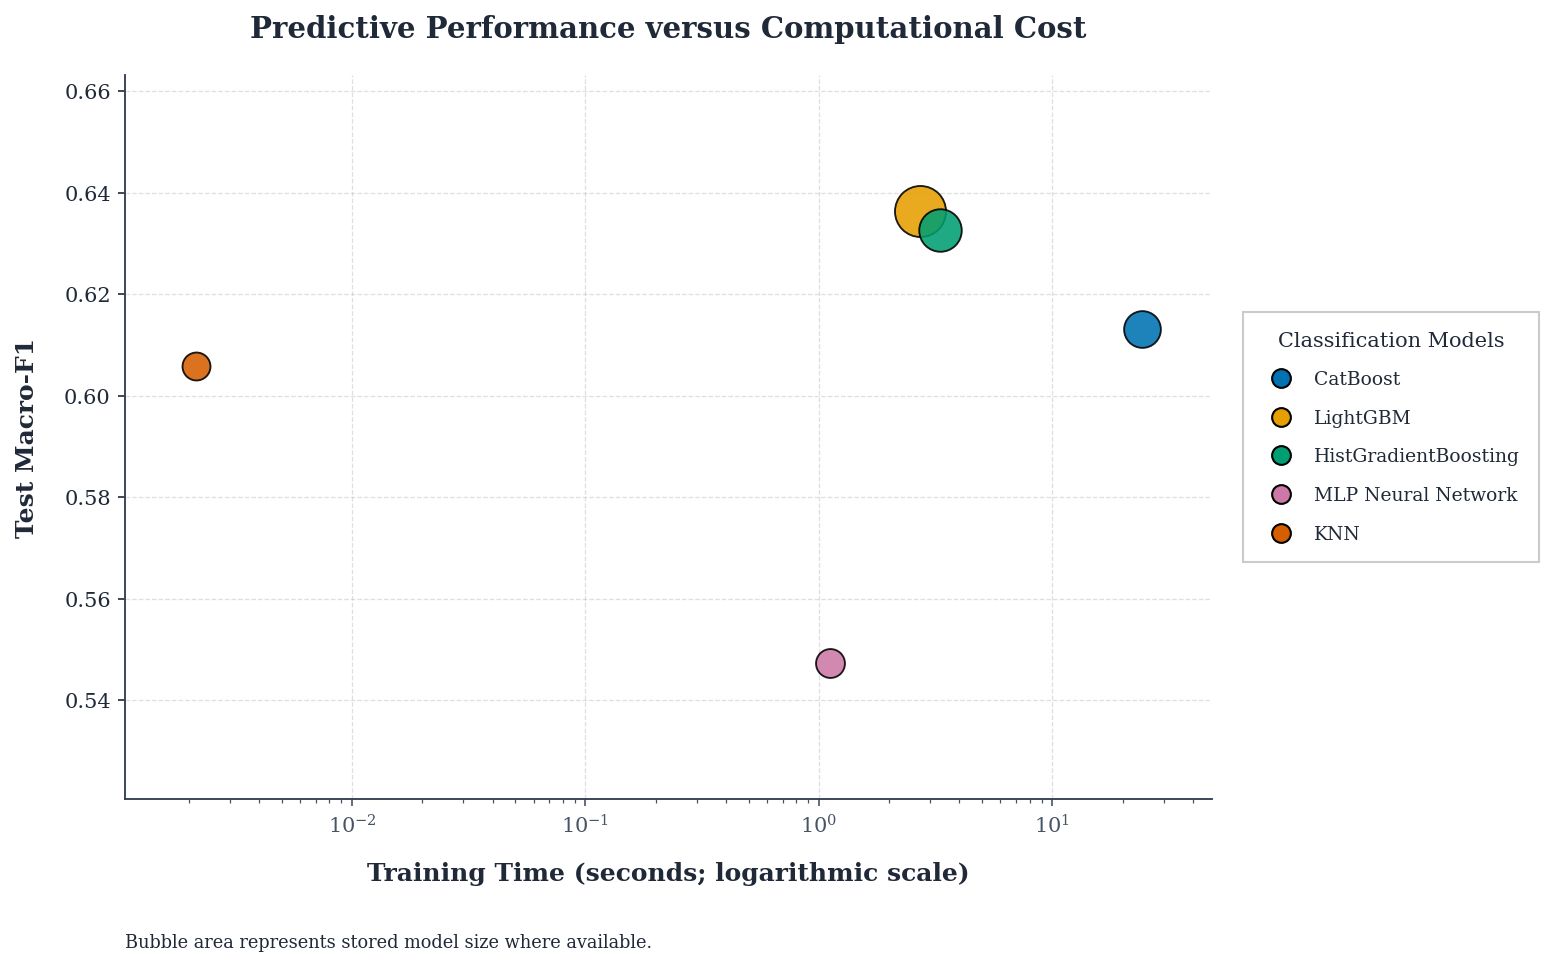

FIGURE 4 GENERATED
PNG: /content/solar_pv_paper_outputs/results/figures/Figure_4_Performance_Computational_Cost.png
PDF: /content/solar_pv_paper_outputs/results/figures/Figure_4_Performance_Computational_Cost.pdf


,Model,Macro_F1,Training_Time_s,Model_Size_MB
0,CatBoost,0.6132,24.1968,1.7667
1,LightGBM,0.6365,2.7014,5.3457
2,HistGradientBoosting,0.6327,3.3197,3.0751
3,MLP Neural Network,0.5473,1.1200,0.2942
4,KNN,0.6059,0.0021,0.1423


In [53]:
# =============================================================================
# FIGURE 4 — PERFORMANCE VERSUS COMPUTATIONAL COST
# Clean IEEE layout with external legend and no overlapping labels
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.lines import Line2D

# =============================================================================
# 1. VALIDATE AND PREPARE RESULTS
# =============================================================================

if "model_outputs" not in globals():
    raise NameError("Run the model evaluation cell first.")

if "RESULT_DIR" not in globals():
    raise NameError("RESULT_DIR is not available.")

FIGURE_DIR = Path(RESULT_DIR) / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

model_order = [
    ("catboost", "CatBoost"),
    ("lgbm", "LightGBM"),
    ("histgb", "HistGradientBoosting"),
    ("mlp", "MLP Neural Network"),
    ("knn", "KNN"),
]

model_colors = {
    "catboost": "#0072B2",
    "lgbm": "#E69F00",
    "histgb": "#009E73",
    "mlp": "#CC79A7",
    "knn": "#D55E00",
}

records = []

for key, label in model_order:

    if key not in model_outputs:
        continue

    result = model_outputs[key].get("result")

    if not isinstance(result, dict):
        continue

    try:
        macro_f1 = float(result["Test_Macro_F1"])
        training_time = float(result["Training_Time_s"])
        model_size = float(result.get("Model_Size_MB", np.nan))
    except (KeyError, TypeError, ValueError):
        print(f"Skipping {label}: required metrics unavailable.")
        continue

    if (
        not np.isfinite(macro_f1)
        or not np.isfinite(training_time)
        or training_time <= 0
    ):
        print(f"Skipping {label}: invalid measurements.")
        continue

    records.append({
        "Key": key,
        "Model": label,
        "Macro_F1": macro_f1,
        "Training_Time_s": training_time,
        "Model_Size_MB": model_size,
    })

results_df = pd.DataFrame(records)

if results_df.empty:
    raise ValueError("No valid model results were found.")

# =============================================================================
# 2. IEEE FORMATTING
# =============================================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "bold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# =============================================================================
# 3. SCALE BUBBLES BY STORED MODEL SIZE
# =============================================================================

model_sizes = results_df["Model_Size_MB"].to_numpy(dtype=float)
valid_sizes = np.isfinite(model_sizes) & (model_sizes >= 0)

bubble_sizes = np.full(len(results_df), 240.0)

if valid_sizes.any():

    minimum_size = model_sizes[valid_sizes].min()
    maximum_size = model_sizes[valid_sizes].max()

    if maximum_size > minimum_size:
        bubble_sizes[valid_sizes] = (
            180
            + 420
            * (model_sizes[valid_sizes] - minimum_size)
            / (maximum_size - minimum_size)
        )
    else:
        bubble_sizes[valid_sizes] = 330.0

# =============================================================================
# 4. CREATE SCATTER PLOT
# =============================================================================

fig, ax = plt.subplots(figsize=(11.5, 6.8))

for index, row in results_df.iterrows():

    ax.scatter(
        row["Training_Time_s"],
        row["Macro_F1"],
        s=bubble_sizes[index],
        color=model_colors[row["Key"]],
        edgecolor="black",
        linewidth=0.9,
        alpha=0.88,
        zorder=3,
    )

# =============================================================================
# 5. AXES AND GRID
# =============================================================================

ax.set_xscale("log")

ax.set_xlabel(
    "Training Time (seconds; logarithmic scale)",
    labelpad=12,
)

ax.set_ylabel(
    "Test Macro-F1",
    labelpad=12,
)

ax.set_title(
    "Predictive Performance versus Computational Cost",
    pad=18,
)

# Include all actual points with modest vertical margins.
y_min = results_df["Macro_F1"].min()
y_max = results_df["Macro_F1"].max()
y_padding = max(0.025, (y_max - y_min) * 0.30)

ax.set_ylim(
    max(0.0, y_min - y_padding),
    min(1.0, y_max + y_padding),
)

x_min = results_df["Training_Time_s"].min()
x_max = results_df["Training_Time_s"].max()

ax.set_xlim(
    x_min / 2.0,
    x_max * 2.0,
)

ax.grid(
    True,
    which="major",
    linestyle="--",
    linewidth=0.6,
    alpha=0.4,
)

ax.set_axisbelow(True)

# =============================================================================
# 6. EXTERNAL MODEL LEGEND
# No direct labels or connector lines are drawn over the data.
# =============================================================================

legend_handles = []

for key, label in model_order:

    if key not in results_df["Key"].values:
        continue

    handle = Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor=model_colors[key],
        markeredgecolor="black",
        markersize=9,
        label=label,
    )

    legend_handles.append(handle)

ax.legend(
    handles=legend_handles,
    title="Classification Models",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=True,
    fancybox=False,
    edgecolor="0.75",
    borderpad=1.0,
    labelspacing=1.1,
)

# Model-size explanation outside the data region.
fig.text(
    0.12,
    0.025,
    "Bubble area represents stored model size where available.",
    fontsize=8.5,
    ha="left",
)

# Reserve room for the legend and bottom note.
fig.subplots_adjust(
    left=0.12,
    right=0.75,
    bottom=0.17,
    top=0.88,
)

# =============================================================================
# 7. SAVE AND DISPLAY
# =============================================================================

png_path = FIGURE_DIR / "Figure_4_Performance_Computational_Cost.png"
pdf_path = FIGURE_DIR / "Figure_4_Performance_Computational_Cost.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
plt.close(fig)

# =============================================================================
# 8. REPORT RESULTS
# =============================================================================

print("=" * 75)
print("FIGURE 4 GENERATED")
print("=" * 75)

print(f"PNG: {png_path}")
print(f"PDF: {pdf_path}")

display(
    results_df[
        ["Model", "Macro_F1", "Training_Time_s", "Model_Size_MB"]
    ].round(4)
)

Skipping HistGradientBoosting: native feature importance is not exposed by this estimator.


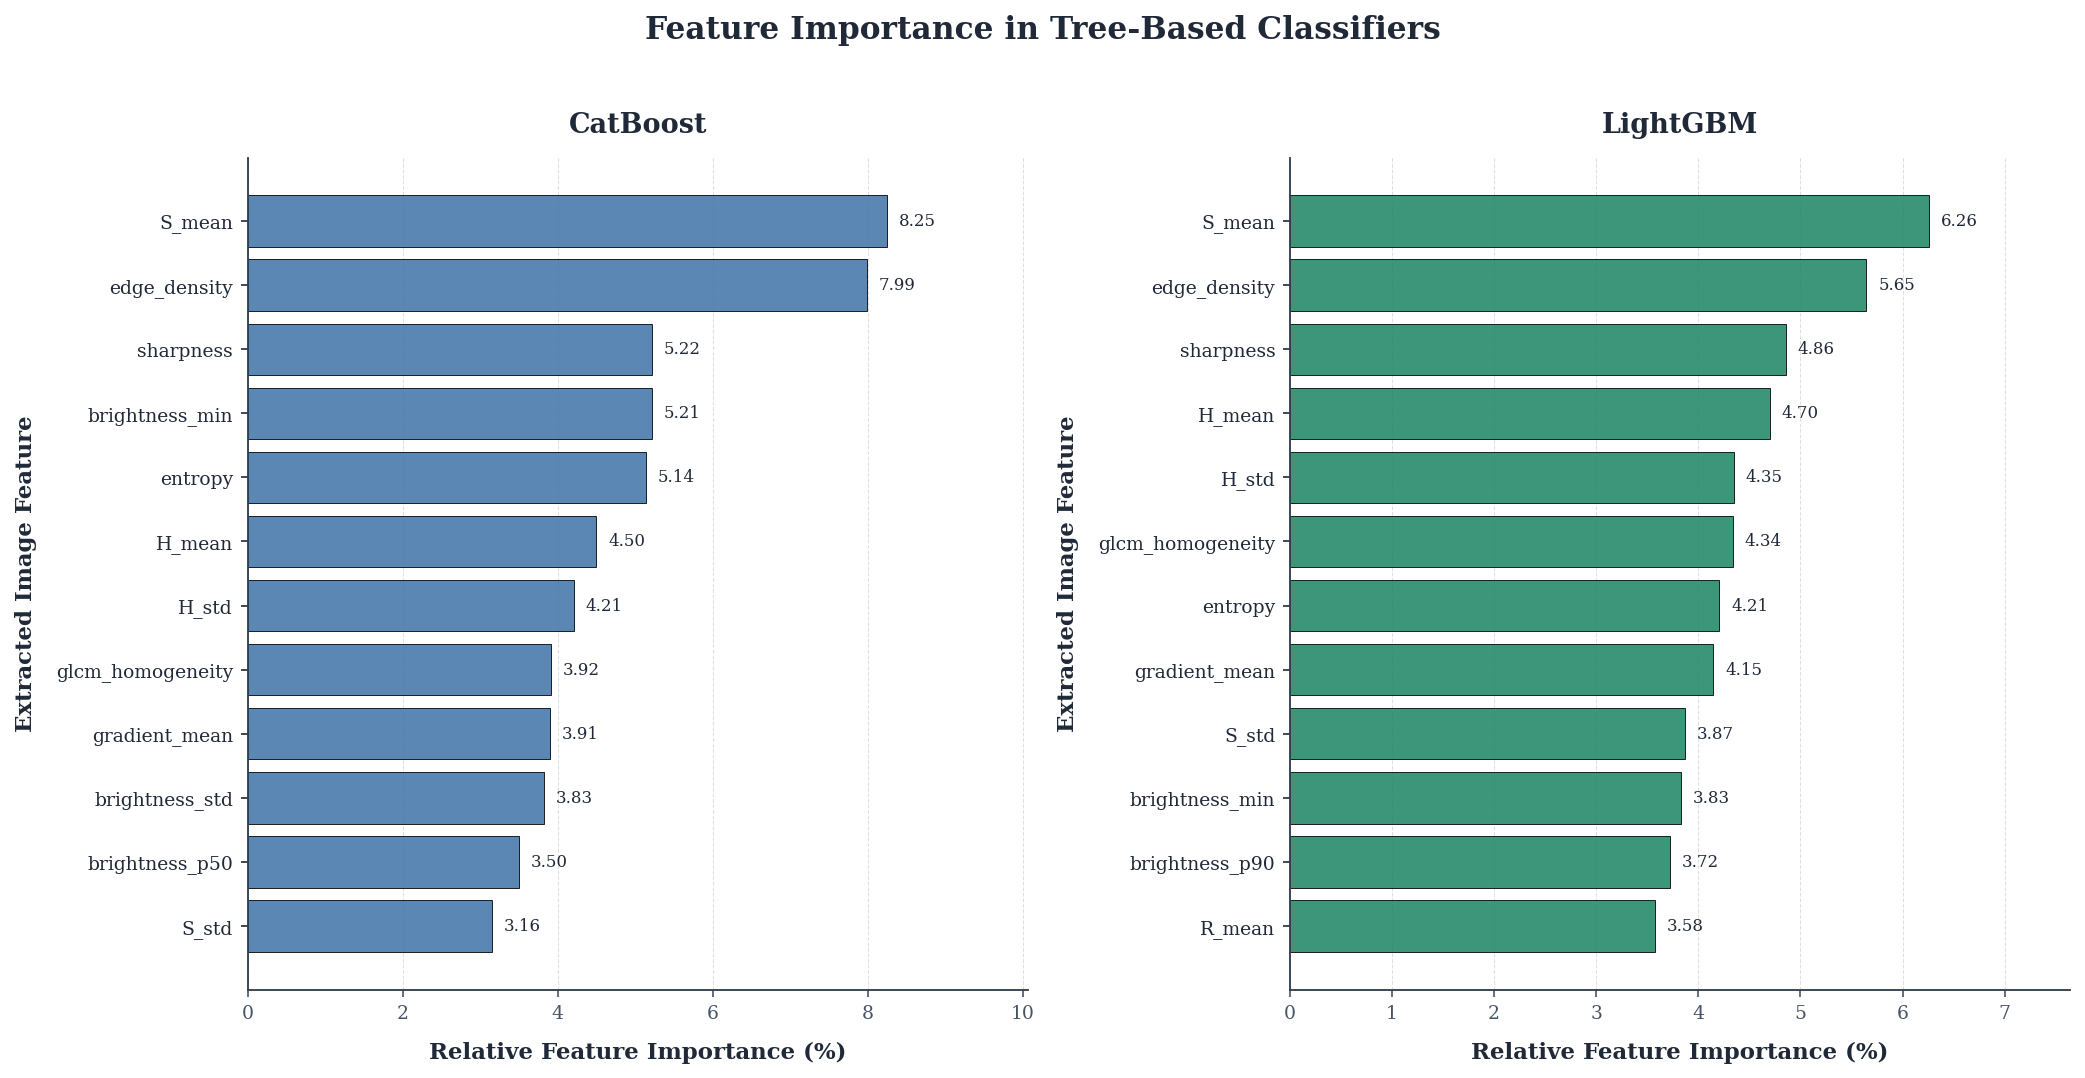

FIGURE 5 GENERATED SUCCESSFULLY
PNG: /content/solar_pv_paper_outputs/results/figures/Figure_5_Tree_Model_Feature_Importance.png
PDF: /content/solar_pv_paper_outputs/results/figures/Figure_5_Tree_Model_Feature_Importance.pdf
Data CSV: /content/solar_pv_paper_outputs/results/Figure_5_Feature_Importance_Data.csv
Models included: ['CatBoost', 'LightGBM']


In [54]:
# =============================================================================
# FIGURE 5 — TREE-MODEL FEATURE IMPORTANCE
# Solar Panel Condition Classification
# IEEE Publication-Quality Visualization
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path


# =============================================================================
# 1. VALIDATE EXISTING RESULTS
# =============================================================================

if "model_outputs" not in globals():
    raise NameError(
        "model_outputs is missing. Run the model evaluation cell first."
    )

if "RESULT_DIR" not in globals():
    raise NameError("RESULT_DIR is missing.")

FIGURE_DIR = Path(RESULT_DIR) / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# =============================================================================
# 2. PUBLICATION FORMATTING
# =============================================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.labelweight": "bold",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# =============================================================================
# 3. RESOLVE FEATURE NAMES
# =============================================================================

def resolve_feature_names(estimator, n_features):
    """
    Recover the original feature names when available.
    Generic names are used only when the mapping cannot be recovered.
    """

    # Prefer known feature-name variables from the feature-engineering pipeline.
    candidate_variables = [
        "feature_names",
        "selected_features",
        "feature_cols",
        "feature_columns",
    ]

    for variable_name in candidate_variables:

        candidate = globals().get(variable_name)

        if candidate is None or isinstance(candidate, str):
            continue

        try:
            names = list(candidate)

            if len(names) == n_features:
                return [str(name) for name in names]

        except TypeError:
            continue

    # Use columns from original feature matrices if available.
    for variable_name in ["X_train_scaled", "X_train"]:

        candidate = globals().get(variable_name)

        if hasattr(candidate, "columns"):

            names = [str(name) for name in candidate.columns]

            if len(names) == n_features:
                return names

    # Try names stored on the fitted estimator.
    for attribute_name in [
        "feature_names_in_",
        "feature_names_",
        "feature_name_",
    ]:

        candidate = getattr(
            estimator,
            attribute_name,
            None,
        )

        if candidate is None:
            continue

        try:
            names = list(candidate)

            if len(names) == n_features:
                return [str(name) for name in names]

        except TypeError:
            continue

    # Use an existing feature-importance table only when its length matches.
    existing_importance_df = globals().get(
        "feature_importance_df"
    )

    if isinstance(existing_importance_df, pd.DataFrame):

        if (
            "Feature" in existing_importance_df.columns
            and len(existing_importance_df) == n_features
        ):
            return (
                existing_importance_df["Feature"]
                .astype(str)
                .tolist()
            )

    print(
        "Warning: Original feature names could not be recovered. "
        "Generic feature labels will be used; verify the feature mapping."
    )

    return [
        f"Feature {index + 1}"
        for index in range(n_features)
    ]


# =============================================================================
# 4. EXTRACT IMPORTANCE FROM AVAILABLE TREE MODELS
# =============================================================================

candidate_models = [
    ("catboost", "CatBoost", "#4477AA"),
    ("lgbm", "LightGBM", "#228866"),
    ("histgb", "HistGradientBoosting", "#CC8844"),
]

importance_records = []

for model_key, model_label, model_color in candidate_models:

    if model_key not in model_outputs:
        continue

    estimator = model_outputs[model_key].get("model")

    if estimator is None:
        print(f"Skipping {model_label}: fitted model not available.")
        continue

    # HistGradientBoostingClassifier often does not expose native
    # feature_importances_; it is skipped unless the attribute exists.
    importances = getattr(
        estimator,
        "feature_importances_",
        None,
    )

    if importances is None:
        print(
            f"Skipping {model_label}: native feature importance "
            "is not exposed by this estimator."
        )
        continue

    importances = np.asarray(
        importances,
        dtype=float,
    ).reshape(-1)

    if (
        len(importances) == 0
        or not np.all(np.isfinite(importances))
        or np.any(importances < 0)
        or importances.sum() <= 0
    ):
        print(f"Skipping {model_label}: importance values are invalid.")
        continue

    feature_names_for_model = resolve_feature_names(
        estimator,
        len(importances),
    )

    # Normalize to percentage of total importance within this model.
    relative_importances = (
        100.0 * importances / importances.sum()
    )

    importance_records.append({
        "key": model_key,
        "name": model_label,
        "color": model_color,
        "features": feature_names_for_model,
        "values": relative_importances,
    })


if not importance_records:
    raise ValueError(
        "No eligible models expose usable feature_importances_. "
        "Check the trained models and their stored outputs."
    )


# =============================================================================
# 5. CREATE SIDE-BY-SIDE FEATURE IMPORTANCE PANELS
# =============================================================================

top_k = 12
number_of_panels = len(importance_records)

fig, axes = plt.subplots(
    nrows=1,
    ncols=number_of_panels,
    figsize=(7.0 * number_of_panels, 7.0),
    squeeze=False,
)

for ax, record in zip(
    axes.ravel(),
    importance_records,
):

    values = record["values"]
    features = record["features"]

    # Select top features, then arrange in ascending importance
    top_indices = np.argsort(values)[-min(top_k, len(values)):]
    top_indices = top_indices[
        np.argsort(values[top_indices])
    ]

    selected_values = values[top_indices]
    selected_features = [
        features[index]
        for index in top_indices
    ]

    bars = ax.barh(
        selected_features,
        selected_values,
        color=record["color"],
        edgecolor="black",
        linewidth=0.45,
        alpha=0.88,
    )

    ax.set_title(
        record["name"],
        pad=12,
    )

    ax.set_xlabel(
        "Relative Feature Importance (%)",
        labelpad=9,
    )

    ax.set_ylabel(
        "Extracted Image Feature",
        labelpad=9,
    )

    # Leave enough space for annotations.
    max_value = max(
        float(selected_values.max()) * 1.22,
        1.0,
    )

    ax.set_xlim(0, max_value)

    for bar, value in zip(
        bars,
        selected_values,
    ):

        ax.text(
            bar.get_width() + max_value * 0.015,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.2f}",
            va="center",
            ha="left",
            fontsize=8,
        )

    ax.grid(
        axis="x",
        linestyle="--",
        linewidth=0.5,
        alpha=0.4,
    )

    ax.set_axisbelow(True)

fig.suptitle(
    "Feature Importance in Tree-Based Classifiers",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)

fig.tight_layout()


# =============================================================================
# 6. SAVE AS PNG AND PDF
# =============================================================================

png_path = (
    FIGURE_DIR
    / "Figure_5_Tree_Model_Feature_Importance.png"
)

pdf_path = (
    FIGURE_DIR
    / "Figure_5_Tree_Model_Feature_Importance.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white",
)


# =============================================================================
# 7. DISPLAY THE FIGURE
# =============================================================================

plt.show()
plt.close(fig)


# =============================================================================
# 8. EXPORT UNDERLYING IMPORTANCE VALUES FOR REPRODUCIBILITY
# =============================================================================

importance_rows = []

for record in importance_records:

    for feature, value in zip(
        record["features"],
        record["values"],
    ):

        importance_rows.append({
            "Model": record["name"],
            "Feature": feature,
            "Relative_Importance_Percent": value,
        })

importance_df = pd.DataFrame(importance_rows)

importance_csv_path = (
    RESULT_DIR
    / "Figure_5_Feature_Importance_Data.csv"
)

importance_df.to_csv(
    importance_csv_path,
    index=False,
)

print("=" * 80)
print("FIGURE 5 GENERATED SUCCESSFULLY")
print("=" * 80)
print(f"PNG: {png_path}")
print(f"PDF: {pdf_path}")
print(f"Data CSV: {importance_csv_path}")
print(f"Models included: {[r['name'] for r in importance_records]}")
print("=" * 80)

FIGURE 6 — PREDICTION-CONFIDENCE SUMMARY


,Model,Correct_Predictions,Incorrect_Predictions,Mean_Confidence_Correct,Median_Confidence_Correct,Mean_Confidence_Incorrect,Median_Confidence_Incorrect
0,HistGradientBoosting,95,38,0.8897,0.9685,0.7959,0.8691
1,LightGBM,93,40,0.9622,0.9983,0.8413,0.9336


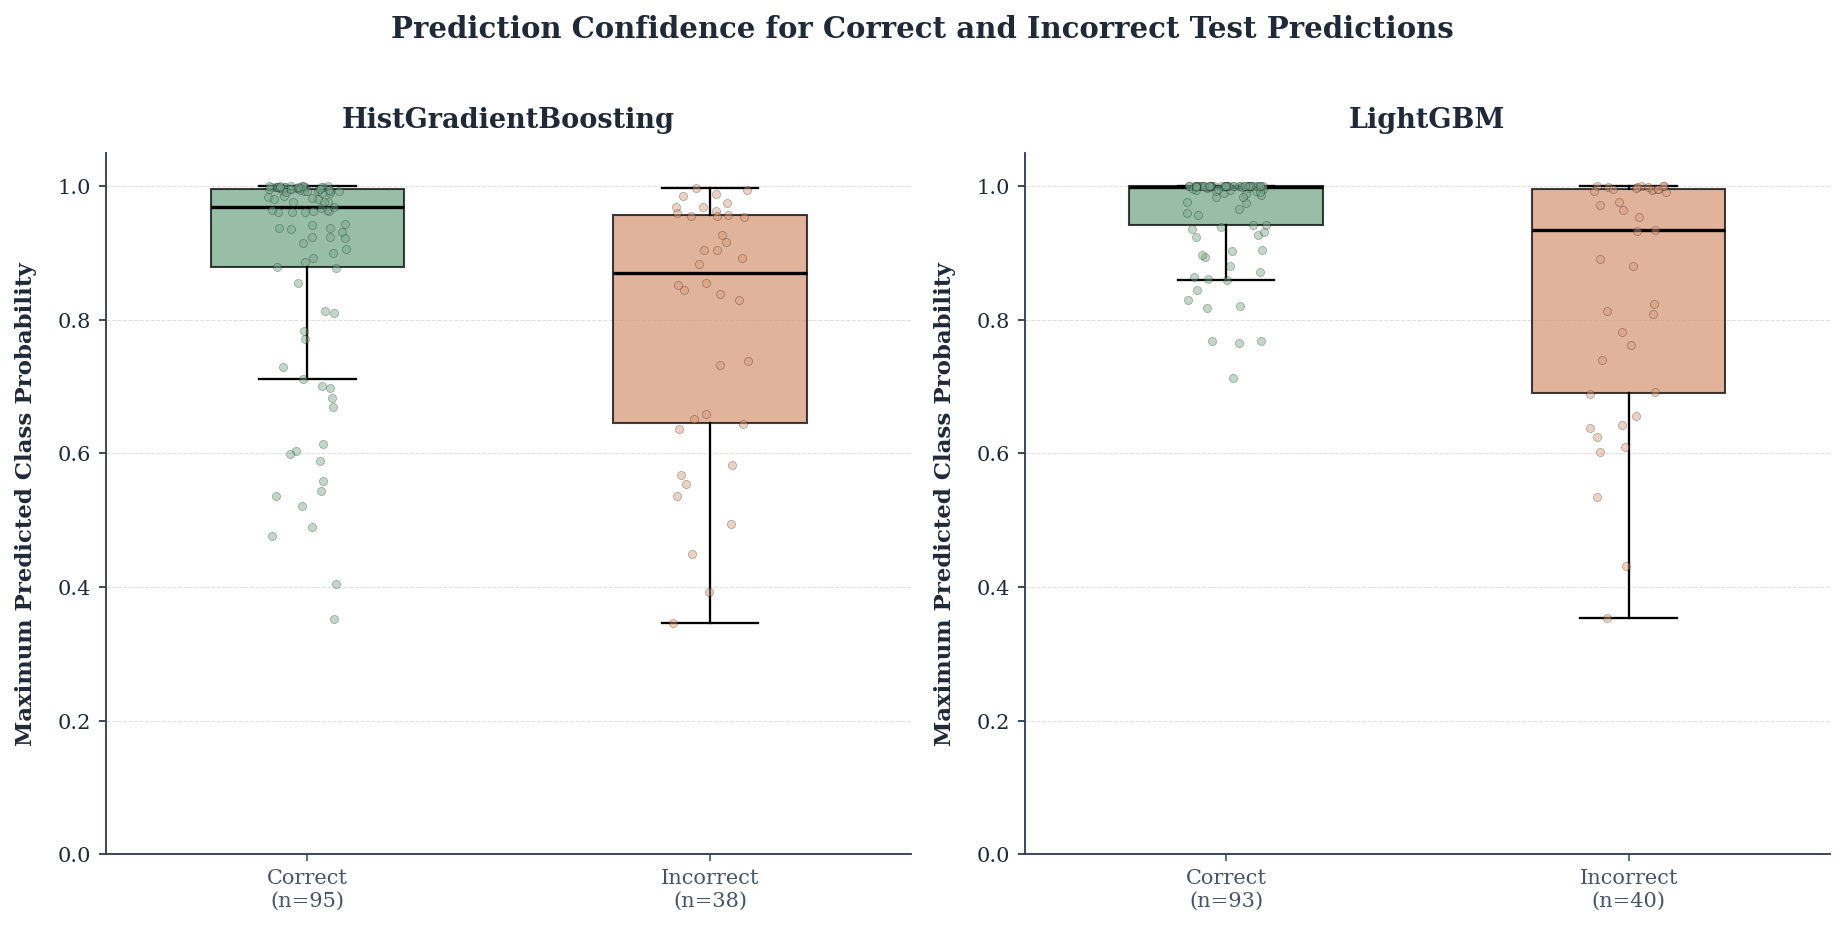


FIGURE 6 GENERATED SUCCESSFULLY
PNG: /content/solar_pv_paper_outputs/results/figures/Figure_6_Prediction_Confidence_Analysis.png
PDF: /content/solar_pv_paper_outputs/results/figures/Figure_6_Prediction_Confidence_Analysis.pdf
Summary CSV: /content/solar_pv_paper_outputs/results/Figure_6_Prediction_Confidence_Summary.csv

Interpretation note: these plots summarize maximum predicted probability for correct versus incorrect predictions. They do not, by themselves, establish probability calibration.


In [55]:
# =============================================================================
# FIGURE 6 — PREDICTION-CONFIDENCE ANALYSIS
# Solar Panel Condition Classification
# IEEE Publication-Quality Visualization
#
# Compares maximum predicted class probability for:
#   1. Correctly classified test images
#   2. Incorrectly classified test images
#
# Models:
#   - HistGradientBoosting
#   - LightGBM
#
# No model retraining is performed.
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path


# =============================================================================
# 1. VALIDATE EXISTING RESULTS
# =============================================================================

if "model_outputs" not in globals():
    raise NameError(
        "model_outputs is missing. Run the model evaluation cell first."
    )

if "y_test" not in globals():
    raise NameError(
        "y_test is missing. Run the data-splitting cell first."
    )

if "RESULT_DIR" not in globals():
    raise NameError(
        "RESULT_DIR is missing. Run the setup cell first."
    )

FIGURE_DIR = Path(RESULT_DIR) / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# =============================================================================
# 2. PUBLICATION-QUALITY FORMATTING
# =============================================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.labelweight": "bold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# =============================================================================
# 3. PREPARE GROUND-TRUTH LABELS
# =============================================================================

y_true = np.asarray(
    y_test.to_numpy() if hasattr(y_test, "to_numpy") else y_test
).reshape(-1)


# =============================================================================
# 4. EXTRACT CONFIDENCE SCORES
# =============================================================================

preferred_models = [
    ("histgb", "HistGradientBoosting", "#4477AA"),
    ("lgbm", "LightGBM", "#228866"),
]

confidence_records = []
summary_records = []

for model_key, model_label, model_color in preferred_models:

    if model_key not in model_outputs:
        print(f"Skipping {model_label}: stored model output unavailable.")
        continue

    output = model_outputs[model_key]

    predictions = output.get("predictions")
    probabilities = output.get("probabilities")

    if predictions is None:
        print(f"Skipping {model_label}: test predictions unavailable.")
        continue

    if probabilities is None:
        print(f"Skipping {model_label}: predicted probabilities unavailable.")
        continue

    if hasattr(predictions, "to_numpy"):
        predictions = predictions.to_numpy()

    predictions = np.asarray(predictions).reshape(-1)

    probabilities = np.asarray(probabilities, dtype=float)

    # Verify probability-array dimensions.
    if probabilities.ndim != 2:
        print(
            f"Skipping {model_label}: probabilities must be a "
            "two-dimensional array."
        )
        continue

    if probabilities.shape[0] != len(y_true):
        print(
            f"Skipping {model_label}: probability count does not "
            "match the test-set size."
        )
        continue

    if len(predictions) != len(y_true):
        print(
            f"Skipping {model_label}: prediction count does not "
            "match the test-set size."
        )
        continue

    if probabilities.shape[1] < 2:
        print(
            f"Skipping {model_label}: probabilities do not contain "
            "multiple class columns."
        )
        continue

    if not np.all(np.isfinite(probabilities)):
        print(
            f"Skipping {model_label}: non-finite probability values found."
        )
        continue

    if np.any(probabilities < -1e-8) or np.any(probabilities > 1 + 1e-8):
        print(
            f"Skipping {model_label}: values fall outside the "
            "expected probability range."
        )
        continue

    # Maximum predicted probability for each test image.
    confidence = np.max(probabilities, axis=1)

    # Correctness determined from stored predictions and ground truth.
    correct_mask = predictions == y_true

    correct_confidence = confidence[correct_mask]
    incorrect_confidence = confidence[~correct_mask]

    # At least one group must contain observations.
    if len(correct_confidence) + len(incorrect_confidence) == 0:
        print(f"Skipping {model_label}: no usable observations.")
        continue

    confidence_records.append({
        "key": model_key,
        "model": model_label,
        "color": model_color,
        "correct": correct_confidence,
        "incorrect": incorrect_confidence,
    })

    summary_records.append({
        "Model": model_label,
        "Correct_Predictions": int(correct_mask.sum()),
        "Incorrect_Predictions": int((~correct_mask).sum()),
        "Mean_Confidence_Correct": (
            float(np.mean(correct_confidence))
            if len(correct_confidence) > 0
            else np.nan
        ),
        "Median_Confidence_Correct": (
            float(np.median(correct_confidence))
            if len(correct_confidence) > 0
            else np.nan
        ),
        "Mean_Confidence_Incorrect": (
            float(np.mean(incorrect_confidence))
            if len(incorrect_confidence) > 0
            else np.nan
        ),
        "Median_Confidence_Incorrect": (
            float(np.median(incorrect_confidence))
            if len(incorrect_confidence) > 0
            else np.nan
        ),
    })


if not confidence_records:
    raise ValueError(
        "No usable probability arrays were found for LightGBM or "
        "HistGradientBoosting. Check model_outputs['lgbm']['probabilities'] "
        "and model_outputs['histgb']['probabilities']."
    )


# =============================================================================
# 5. DISPLAY NUMERICAL CONFIDENCE SUMMARY
# =============================================================================

confidence_summary_df = pd.DataFrame(summary_records)

print("=" * 85)
print("FIGURE 6 — PREDICTION-CONFIDENCE SUMMARY")
print("=" * 85)

display(confidence_summary_df.round(4))


# =============================================================================
# 6. CREATE SIDE-BY-SIDE CONFIDENCE BOXPLOTS
# =============================================================================

fig, axes = plt.subplots(
    1,
    len(confidence_records),
    figsize=(6.2 * len(confidence_records), 6.0),
    squeeze=False,
)

rng = np.random.default_rng(42)

for ax, record in zip(axes.ravel(), confidence_records):

    groups = []
    group_labels = []
    group_colors = []

    if len(record["correct"]) > 0:
        groups.append(record["correct"])
        group_labels.append(
            f"Correct\n(n={len(record['correct'])})"
        )
        group_colors.append("#76A88B")

    if len(record["incorrect"]) > 0:
        groups.append(record["incorrect"])
        group_labels.append(
            f"Incorrect\n(n={len(record['incorrect'])})"
        )
        group_colors.append("#D99A7A")

    positions = np.arange(1, len(groups) + 1)

    boxplot = ax.boxplot(
        groups,
        positions=positions,
        widths=0.48,
        patch_artist=True,
        showfliers=False,
        medianprops={
            "color": "black",
            "linewidth": 1.6,
        },
        whiskerprops={
            "linewidth": 1.1,
        },
        capprops={
            "linewidth": 1.1,
        },
    )

    for patch, color in zip(
        boxplot["boxes"],
        group_colors,
    ):
        patch.set_facecolor(color)
        patch.set_edgecolor("black")
        patch.set_alpha(0.75)

    # Overlay a small, deterministic sample of points when the sample
    # count is large, so the distribution remains visible without crowding.
    for position, values, color in zip(
        positions,
        groups,
        group_colors,
    ):

        if len(values) > 150:
            selected_indices = rng.choice(
                len(values),
                size=150,
                replace=False,
            )
            values_to_plot = values[selected_indices]
        else:
            values_to_plot = values

        jitter = rng.uniform(
            -0.10,
            0.10,
            size=len(values_to_plot),
        )

        ax.scatter(
            position + jitter,
            values_to_plot,
            s=15,
            color=color,
            edgecolors="black",
            linewidths=0.25,
            alpha=0.45,
            zorder=3,
        )

    ax.set_xticks(
        positions,
        labels=group_labels,
    )

    ax.set_xlim(0.5, len(groups) + 0.5)
    ax.set_ylim(0, 1.05)

    ax.set_ylabel(
        "Maximum Predicted Class Probability",
        labelpad=10,
    )

    ax.set_title(
        record["model"],
        pad=12,
    )

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.5,
        alpha=0.4,
    )

    ax.set_axisbelow(True)

fig.suptitle(
    "Prediction Confidence for Correct and Incorrect Test Predictions",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)

fig.tight_layout()


# =============================================================================
# 7. SAVE AS PNG AND PDF
# =============================================================================

png_path = (
    FIGURE_DIR
    / "Figure_6_Prediction_Confidence_Analysis.png"
)

pdf_path = (
    FIGURE_DIR
    / "Figure_6_Prediction_Confidence_Analysis.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white",
)


# =============================================================================
# 8. DISPLAY THE FIGURE
# =============================================================================

plt.show()
plt.close(fig)


# =============================================================================
# 9. SAVE NUMERICAL SUMMARY
# =============================================================================

summary_csv_path = (
    RESULT_DIR
    / "Figure_6_Prediction_Confidence_Summary.csv"
)

confidence_summary_df.to_csv(
    summary_csv_path,
    index=False,
)


# =============================================================================
# 10. COMPLETION SUMMARY
# =============================================================================

print("\n" + "=" * 85)
print("FIGURE 6 GENERATED SUCCESSFULLY")
print("=" * 85)

print(f"PNG: {png_path}")
print(f"PDF: {pdf_path}")
print(f"Summary CSV: {summary_csv_path}")

print(
    "\nInterpretation note: these plots summarize maximum predicted "
    "probability for correct versus incorrect predictions. They do not, "
    "by themselves, establish probability calibration."
)

print("=" * 85)

CatBoost                 | Macro-average ROC-AUC = 0.8867
LightGBM                 | Macro-average ROC-AUC = 0.8901
HistGradientBoosting     | Macro-average ROC-AUC = 0.9012
MLP Neural Network       | Macro-average ROC-AUC = 0.8863
KNN                      | Macro-average ROC-AUC = 0.8488


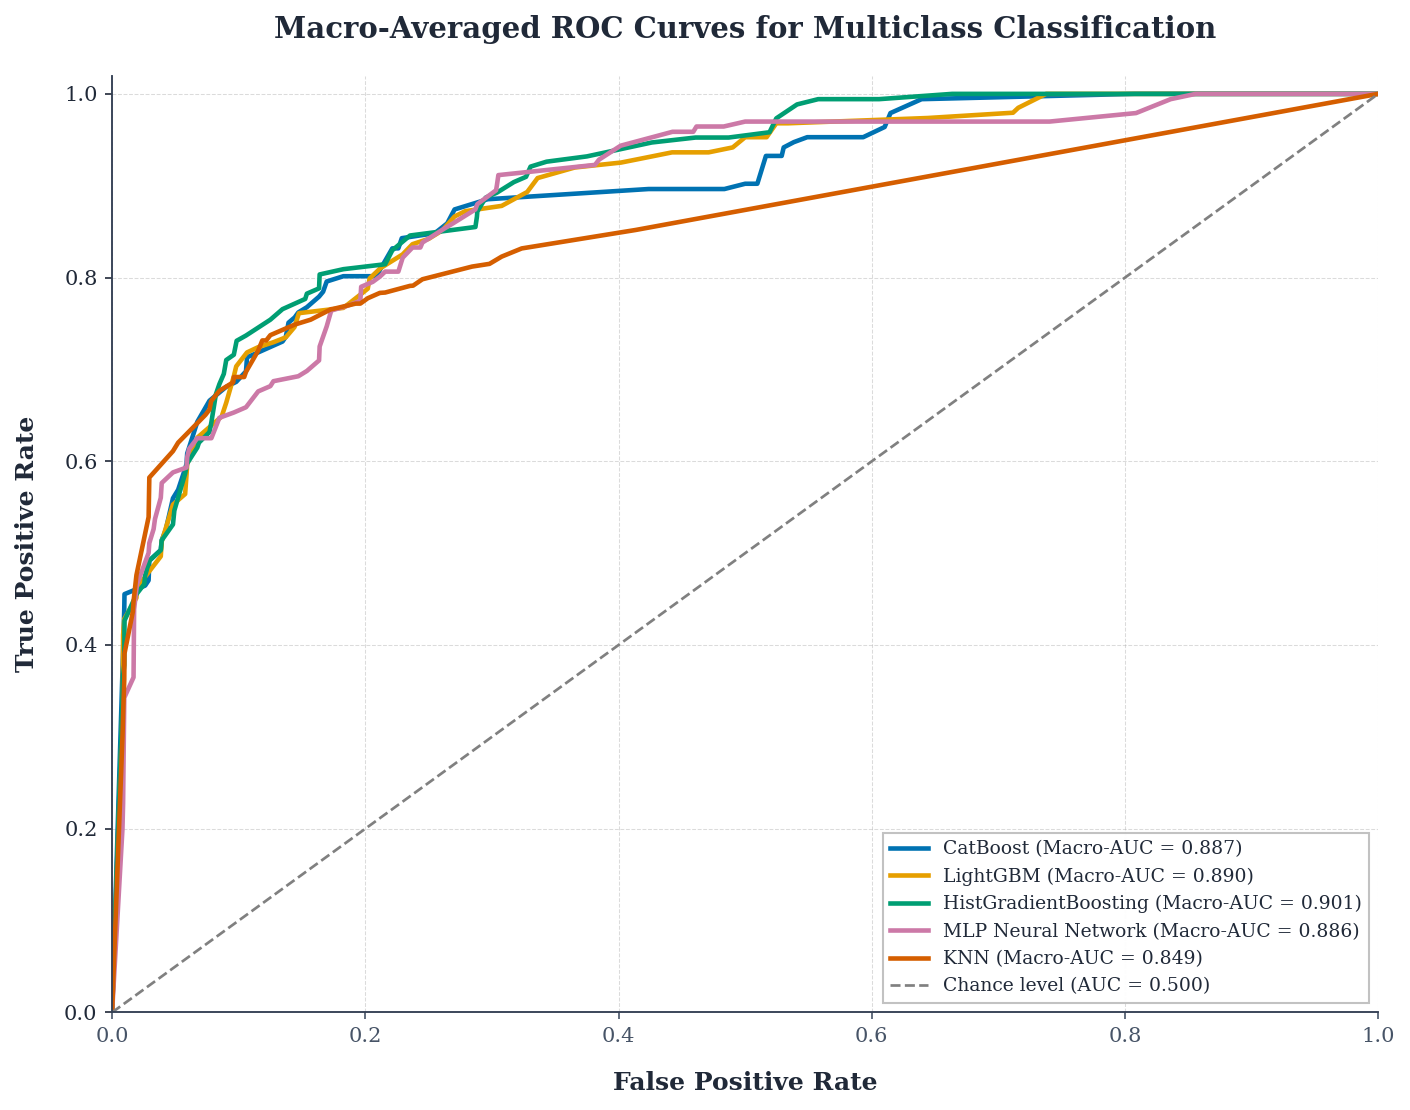


FIGURE 7 — MULTICLASS ROC ANALYSIS COMPLETED
PNG: /content/solar_pv_paper_outputs/results/figures/Figure_7_Multiclass_ROC_Curves.png
PDF: /content/solar_pv_paper_outputs/results/figures/Figure_7_Multiclass_ROC_Curves.pdf
AUC summary CSV: /content/solar_pv_paper_outputs/results/Figure_7_ROC_AUC_Summary.csv

Macro-average ROC-AUC ranking:


,Model,ROC_AUC
0,HistGradientBoosting,0.9012
1,LightGBM,0.8901
2,CatBoost,0.8867
3,MLP Neural Network,0.8863
4,KNN,0.8488



Interpretation: a larger ROC-AUC indicates stronger ranking discrimination in this test set. It does not alone establish calibration or superiority on unseen datasets.


In [56]:
# =============================================================================
# FIGURE 7 — MULTICLASS ROC CURVE COMPARISON
# Solar Panel Condition Classification
# IEEE Publication-Quality Visualization
#
# Method:
#   One-vs-Rest (OvR) ROC
#   Macro-average ROC across classes
#
# Models:
#   CatBoost, LightGBM, HistGradientBoosting,
#   MLP Neural Network, KNN
#
# Outputs:
#   300-DPI PNG
#   Vector PDF
#   CSV with macro and per-class ROC-AUC results
#
# No models are retrained.
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import roc_curve, auc


# =============================================================================
# 1. VALIDATE EXPERIMENTAL OUTPUTS
# =============================================================================

if "model_outputs" not in globals():
    raise NameError(
        "model_outputs is missing. Run the model evaluation cell first."
    )

if "y_test" not in globals():
    raise NameError("y_test is not available.")

if "RESULT_DIR" not in globals():
    raise NameError("RESULT_DIR is not available.")

FIGURE_DIR = Path(RESULT_DIR) / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# =============================================================================
# 2. PUBLICATION FORMATTING
# =============================================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "bold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.linewidth": 0.9,
})


# =============================================================================
# 3. TEST LABELS AND MODEL DEFINITIONS
# =============================================================================

y_true = np.asarray(
    y_test.to_numpy() if hasattr(y_test, "to_numpy") else y_test
).reshape(-1)

# Sorted class labels represented in the test set
class_values = np.unique(y_true)
n_classes = len(class_values)

if n_classes < 2:
    raise ValueError(
        "ROC analysis requires at least two classes in the test set."
    )

model_order = [
    ("catboost", "CatBoost", "#0072B2"),
    ("lgbm", "LightGBM", "#E69F00"),
    ("histgb", "HistGradientBoosting", "#009E73"),
    ("mlp", "MLP Neural Network", "#CC79A7"),
    ("knn", "KNN", "#D55E00"),
]


# =============================================================================
# 4. COMPUTE ONE-VS-REST ROC CURVES FOR EACH MODEL
# =============================================================================

roc_records = []
auc_summary_rows = []
skipped_models = []

for model_key, model_name, color in model_order:

    if model_key not in model_outputs:
        print(f"Skipping {model_name}: model output is unavailable.")
        continue

    output = model_outputs[model_key]

    probabilities = output.get("probabilities")
    estimator = output.get("model")

    if probabilities is None:
        skipped_models.append({
            "Model": model_name,
            "Reason": "Predicted probabilities are unavailable.",
        })
        print(f"Skipping {model_name}: predicted probabilities unavailable.")
        continue

    if estimator is None or not hasattr(estimator, "classes_"):
        skipped_models.append({
            "Model": model_name,
            "Reason": "Fitted model class ordering is unavailable.",
        })
        print(f"Skipping {model_name}: model class ordering unavailable.")
        continue

    probabilities = np.asarray(probabilities, dtype=float)
    estimator_classes = np.asarray(estimator.classes_)

    if probabilities.ndim != 2:
        skipped_models.append({
            "Model": model_name,
            "Reason": "Probability output is not two-dimensional.",
        })
        print(f"Skipping {model_name}: invalid probability dimensions.")
        continue

    if probabilities.shape[0] != len(y_true):
        skipped_models.append({
            "Model": model_name,
            "Reason": "Probability count does not match test labels.",
        })
        print(f"Skipping {model_name}: test sample counts do not match.")
        continue

    if probabilities.shape[1] != len(estimator_classes):
        skipped_models.append({
            "Model": model_name,
            "Reason": "Probability columns do not match estimator classes.",
        })
        print(f"Skipping {model_name}: probability-column mismatch.")
        continue

    if not np.all(np.isfinite(probabilities)):
        skipped_models.append({
            "Model": model_name,
            "Reason": "Non-finite probability values detected.",
        })
        print(f"Skipping {model_name}: non-finite probabilities detected.")
        continue

    # Align each test class with its actual predict_proba column.
    class_column_indices = []

    class_mapping_valid = True

    for class_value in class_values:

        matches = np.flatnonzero(
            estimator_classes == class_value
        )

        if len(matches) != 1:
            class_mapping_valid = False
            break

        class_column_indices.append(int(matches[0]))

    if not class_mapping_valid:
        skipped_models.append({
            "Model": model_name,
            "Reason": "Test labels could not be matched to probability columns.",
        })
        print(
            f"Skipping {model_name}: could not reliably align "
            "test classes with predicted probability columns."
        )
        continue

    # Ensure probabilities behave like class probabilities.
    row_sums = probabilities.sum(axis=1)

    if (
        np.any(probabilities < -1e-8)
        or np.any(probabilities > 1 + 1e-8)
        or not np.allclose(row_sums, 1.0, atol=1e-3)
    ):
        skipped_models.append({
            "Model": model_name,
            "Reason": "Probability output failed probability-range checks.",
        })
        print(
            f"Skipping {model_name}: probability values require inspection."
        )
        continue

    # One ROC curve for each class, using that class versus all others.
    class_fprs = []
    class_tprs = []
    class_auc_values = []

    class_results = []

    for class_index, class_value in enumerate(class_values):

        actual_binary = (
            y_true == class_value
        ).astype(int)

        scores = probabilities[
            :,
            class_column_indices[class_index]
        ]

        # A test split containing this class and at least one other class
        # supports a One-vs-Rest ROC calculation.
        if len(np.unique(actual_binary)) != 2:
            print(
                f"Warning: cannot calculate ROC for class "
                f"{class_value} in {model_name}."
            )
            continue

        fpr, tpr, _ = roc_curve(
            actual_binary,
            scores,
        )

        class_auc = auc(fpr, tpr)

        class_fprs.append(fpr)
        class_tprs.append(tpr)
        class_auc_values.append(class_auc)

        class_results.append({
            "Model": model_name,
            "Class": str(class_value),
            "ROC_AUC": float(class_auc),
            "Positive_Test_Samples": int(actual_binary.sum()),
        })

    if len(class_fprs) != n_classes:
        skipped_models.append({
            "Model": model_name,
            "Reason": "Not all test classes supported ROC calculation.",
        })
        print(
            f"Skipping {model_name}: ROC curves were not available "
            "for every test class."
        )
        continue

    # Macro-average ROC: interpolate each class curve onto a shared
    # false-positive-rate grid, then average the true-positive rates.
    all_fpr = np.unique(
        np.concatenate(class_fprs)
    )

    mean_tpr = np.zeros_like(all_fpr)

    for fpr, tpr in zip(class_fprs, class_tprs):
        mean_tpr += np.interp(all_fpr, fpr, tpr)

    mean_tpr /= n_classes

    mean_tpr[0] = 0.0
    mean_tpr[-1] = 1.0

    macro_auc = auc(
        all_fpr,
        mean_tpr,
    )

    roc_records.append({
        "key": model_key,
        "name": model_name,
        "color": color,
        "fpr": all_fpr,
        "tpr": mean_tpr,
        "macro_auc": float(macro_auc),
    })

    auc_summary_rows.extend(class_results)

    auc_summary_rows.append({
        "Model": model_name,
        "Class": "Macro-average",
        "ROC_AUC": float(macro_auc),
        "Positive_Test_Samples": np.nan,
    })

    print(
        f"{model_name:24s} | "
        f"Macro-average ROC-AUC = {macro_auc:.4f}"
    )


# =============================================================================
# 5. CHECK FOR VALID ROC CURVES
# =============================================================================

if not roc_records:
    raise ValueError(
        "No valid ROC curves were generated. Check probability outputs, "
        "the fitted models' classes_, and consistency with y_test."
    )


# =============================================================================
# 6. CREATE MULTICLASS ROC FIGURE
# =============================================================================

fig, ax = plt.subplots(
    figsize=(9.5, 7.5)
)

# Plot each model's macro-average ROC curve.
for record in roc_records:

    ax.plot(
        record["fpr"],
        record["tpr"],
        color=record["color"],
        linewidth=2.2,
        label=(
            f"{record['name']} "
            f"(Macro-AUC = {record['macro_auc']:.3f})"
        ),
    )

# Random-classifier reference.
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.3,
    color="gray",
    label="Chance level (AUC = 0.500)",
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.set_xlabel(
    "False Positive Rate",
    labelpad=12,
)

ax.set_ylabel(
    "True Positive Rate",
    labelpad=12,
)

ax.set_title(
    "Macro-Averaged ROC Curves for Multiclass Classification",
    pad=18,
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.5,
    alpha=0.45,
)

ax.set_axisbelow(True)

ax.legend(
    loc="lower right",
    frameon=True,
    fancybox=False,
    edgecolor="0.75",
    framealpha=0.95,
)

fig.tight_layout()


# =============================================================================
# 7. SAVE AS PNG AND PDF
# =============================================================================

png_path = FIGURE_DIR / "Figure_7_Multiclass_ROC_Curves.png"
pdf_path = FIGURE_DIR / "Figure_7_Multiclass_ROC_Curves.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white",
)


# =============================================================================
# 8. DISPLAY FIGURE
# =============================================================================

plt.show()
plt.close(fig)


# =============================================================================
# 9. SAVE AUC RESULTS
# =============================================================================

auc_summary_df = pd.DataFrame(auc_summary_rows)

auc_csv_path = RESULT_DIR / "Figure_7_ROC_AUC_Summary.csv"

auc_summary_df.to_csv(
    auc_csv_path,
    index=False,
)

print("\n" + "=" * 85)
print("FIGURE 7 — MULTICLASS ROC ANALYSIS COMPLETED")
print("=" * 85)

print(f"PNG: {png_path}")
print(f"PDF: {pdf_path}")
print(f"AUC summary CSV: {auc_csv_path}")

print("\nMacro-average ROC-AUC ranking:")
display(
    auc_summary_df[
        auc_summary_df["Class"] == "Macro-average"
    ][["Model", "ROC_AUC"]]
    .sort_values("ROC_AUC", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

if skipped_models:
    print("\nModels or analyses skipped:")
    display(pd.DataFrame(skipped_models))

print(
    "\nInterpretation: a larger ROC-AUC indicates stronger ranking "
    "discrimination in this test set. It does not alone establish "
    "calibration or superiority on unseen datasets."
)

print("=" * 85)

In [58]:
# =============================================================================
# DOWNLOAD ALL SOLAR PANEL RESEARCH FIGURES FROM THE BEGINNING
#
# Collects figures from all project output folders, including earlier EDA
# figures and the newly generated Figures 1–7.
#
# Formats: PNG, PDF, SVG, EPS
# Output: One ZIP archive downloaded to your computer.
# =============================================================================

from pathlib import Path
from collections import Counter
import zipfile
from google.colab import files

# =============================================================================
# 1. IDENTIFY ALL PROJECT OUTPUT DIRECTORIES
# =============================================================================

candidate_roots = []

for variable_name in [
    "OUTPUT_DIR",
    "RESULT_DIR",
    "FIGURE_DIR",
]:

    candidate = globals().get(variable_name)

    if candidate is not None:
        path = Path(candidate).expanduser()

        if path.exists() and path.is_dir():
            candidate_roots.append(path.resolve())

# Include the standard project output folder if it exists.
default_output = Path(
    "/content/solar_pv_paper_outputs"
)

if default_output.exists() and default_output.is_dir():
    candidate_roots.append(default_output.resolve())

# Remove duplicate roots.
candidate_roots = sorted(
    set(candidate_roots),
    key=lambda path: (len(path.parts), str(path)),
)

# Remove roots already covered by a parent project output directory.
search_roots = []

for candidate in candidate_roots:

    already_covered = any(
        candidate == existing
        or existing in candidate.parents
        for existing in search_roots
    )

    if not already_covered:
        search_roots.append(candidate)

if not search_roots:
    raise FileNotFoundError(
        "No project output directories were found. "
        "Check OUTPUT_DIR, RESULT_DIR, and FIGURE_DIR."
    )

print("=" * 85)
print("SOLAR PANEL RESEARCH — COMPLETE FIGURE COLLECTION")
print("=" * 85)

print("\nProject folders searched:")

for root in search_roots:
    print(f"  {root}")


# =============================================================================
# 2. FIND FIGURES RECURSIVELY
# =============================================================================

figure_extensions = {
    ".png",
    ".pdf",
    ".svg",
    ".eps",
}

excluded_directory_names = {
    "solar_panel_data-1",
    "dataset",
    "datasets",
    "raw_images",
    "original_images",
    "source_images",
    "__pycache__",
    ".ipynb_checkpoints",
}

figure_files = set()

for root in search_roots:

    for path in root.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in figure_extensions:
            continue

        # Prevent collecting original dataset files.
        if any(
            part.lower() in excluded_directory_names
            for part in path.parts
        ):
            continue

        # Exclude hidden intermediate files.
        if any(
            part.startswith(".")
            for part in path.relative_to(root).parts
        ):
            continue

        figure_files.add(path.resolve())

figure_files = sorted(
    figure_files,
    key=lambda path: str(path).lower(),
)

if not figure_files:
    raise FileNotFoundError(
        "No PNG, PDF, SVG, or EPS figures were found. "
        "Check whether earlier figure files still exist in your "
        "Google Colab runtime."
    )


# =============================================================================
# 3. PREPARE DOWNLOAD LOCATION
# =============================================================================

zip_path = Path(
    "/content/Solar_Panel_All_Figures_From_Start.zip"
)

manifest_path = Path(
    "/content/Solar_Panel_Figure_Manifest.txt"
)


# =============================================================================
# 4. PACKAGE ALL FIGURES
# =============================================================================

extension_counts = Counter()

with zipfile.ZipFile(
    zip_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:

    for figure_path in figure_files:

        # Preserve project folder structure inside the ZIP.
        try:
            archive_name = figure_path.relative_to(
                Path("/content").resolve()
            )
        except ValueError:
            archive_name = Path(
                figure_path.parent.name
            ) / figure_path.name

        archive.write(
            figure_path,
            arcname=str(archive_name),
        )

        extension_counts[
            figure_path.suffix.lower()
        ] += 1

        print(f"Added: {archive_name}")

    # Include a manifest identifying every collected figure.
    manifest_lines = [
        "SOLAR PANEL RESEARCH — FIGURE MANIFEST",
        "=" * 70,
        f"Total figure files: {len(figure_files)}",
        "",
    ]

    for figure_path in figure_files:
        manifest_lines.append(str(figure_path))

    archive.writestr(
        "FIGURE_MANIFEST.txt",
        "\n".join(manifest_lines),
    )


# Also save the manifest separately.
manifest_path.write_text(
    "\n".join(manifest_lines),
    encoding="utf-8",
)


# =============================================================================
# 5. REPORT PACKAGE SUMMARY
# =============================================================================

print("\n" + "=" * 85)
print("COMPLETE FIGURE PACKAGE CREATED")
print("=" * 85)

print(f"Total unique figure files: {len(figure_files)}")

for extension in sorted(extension_counts):
    print(f"{extension.upper():8s}: {extension_counts[extension]}")

print(f"\nZIP archive: {zip_path}")
print(f"Manifest:    {manifest_path}")
print(f"ZIP size:    {zip_path.stat().st_size / (1024 ** 2):.2f} MB")

print("\nNote: Only figure files currently present in the searched")
print("project output directories can be included.")
print("=" * 85)


# =============================================================================
# 6. DOWNLOAD THE COMPLETE ZIP
# =============================================================================

files.download(str(zip_path))

SOLAR PANEL RESEARCH — COMPLETE FIGURE COLLECTION

Project folders searched:
  /content/solar_pv_figures
  /content/solar_pv_paper_outputs
Added: solar_pv_paper_outputs/figures/Figure_1_Class_Distribution.pdf
Added: solar_pv_paper_outputs/figures/Figure_1_Class_Distribution.png
Added: solar_pv_paper_outputs/figures/Figure_1_Multimetric_Performance_Heatmap.pdf
Added: solar_pv_paper_outputs/figures/Figure_1_Multimetric_Performance_Heatmap.png
Added: solar_pv_paper_outputs/figures/Figure_1_Visual_Statistical_Profile.pdf
Added: solar_pv_paper_outputs/figures/Figure_1_Visual_Statistical_Profile.png
Added: solar_pv_paper_outputs/figures/Figure_2_Per_Class_Recall_Heatmap.pdf
Added: solar_pv_paper_outputs/figures/Figure_2_Per_Class_Recall_Heatmap.png
Added: solar_pv_paper_outputs/figures/Figure_3_Confusion_Matrix_Comparison.pdf
Added: solar_pv_paper_outputs/figures/Figure_3_Confusion_Matrix_Comparison.png
Added: solar_pv_paper_outputs/figures/Figure_4_Handcrafted_Feature_Space.pdf
Added: solar

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>